In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from scipy import stats as sps
import os, warnings, time

# --- Group configuration ---
group_csv   = "group_gh_ssids.csv"
group_label = "Group G+H"
group_short = "group_gh"

# --- Paths ---
elpac_clean_dir = "../1095 Data/ELPAC/Cleaned"
enrollment_dir  = "../1095 Data/Enrollment"
os.makedirs("plots", exist_ok=True)

# --- Analysis parameters ---
MIN_CELL       = 25    # minimum students per category level
MIN_DISTRICT   = 15    # minimum students per district
MIN_COUNTRY    = 100   # minimum students to keep a birth country separate

pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 200)

print(f"Configured for {group_label}")

# --- CALPADS RaceEthnicity code labels (verified against StudentRace1Code) ---
race_labels = {
    "A": "Asian",
    "B": "Black",
    "D": "NotReported",
    "F": "Filipino",
    "H": "Hispanic_Latino",
    "I": "AmerIndian_AKNative",
    "P": "PacificIslander",
    "T": "TwoOrMore",
    "W": "White",
}
# --- Birth country code → name (ISO 3166-1 alpha-2, plus CALPADS extras) ---
country_labels = {
    # Above the 100-student threshold in this cohort
    "AF": "Afghanistan",   "AM": "Armenia",     "CN": "China",
    "CO": "Colombia",      "GT": "Guatemala",   "HN": "Honduras",
    "HT": "Haiti",         "MX": "Mexico",      "NI": "Nicaragua",
    "RU": "Russia",        "SV": "El Salvador", "UA": "Ukraine",
    "VN": "Vietnam",
    # Non-country levels created by the collapsing step
    "UU": "Unknown",       "Other": "Other (pooled)",  "Missing": "Missing",
    # Below threshold here, but retained in case MIN_COUNTRY is lowered
    "BR": "Brazil",        "PE": "Peru",        "EC": "Ecuador",
    "PH": "Philippines",   "KR": "South Korea", "JP": "Japan",
    "IN": "India",         "PK": "Pakistan",    "BD": "Bangladesh",
    "IQ": "Iraq",          "SY": "Syria",       "YE": "Yemen",
    "EG": "Egypt",         "ET": "Ethiopia",    "SO": "Somalia",
    "KZ": "Kazakhstan",    "UZ": "Uzbekistan",  "MD": "Moldova",
    "BY": "Belarus",       "TH": "Thailand",    "KH": "Cambodia",
    "MM": "Myanmar",       "TR": "Turkey",      "IR": "Iran",
    "JO": "Jordan",        "LB": "Lebanon",     "VE": "Venezuela",
    "AR": "Argentina",     "CL": "Chile",       "DO": "Dominican Rep.",
    "CU": "Cuba",          "TW": "Taiwan",      "HK": "Hong Kong",
    "FJ": "Fiji",          "NP": "Nepal",       "UM": "U.S. Outlying",
    "US": "United States",
}
print(f"Loaded {len(country_labels)} birth country labels")
# --- Outcome switch: flip to Z after seeing Cell 3's verdict ---
#OUTCOME  = "ZGain_fixed"      # or "ZGain_fixed"  (orig: "ScoreGain")
OUTCOME  = "ScoreGain"      # or "ZGain_fixed"  (orig: "ScoreGain")
BASELINE = "S1_wg"         # or "Z1_fixed" (orig: "Summ1Score_c")

print(f"Outcome: {OUTCOME}, baseline covariate: {BASELINE}")

Configured for Group G+H
Loaded 53 birth country labels
Outcome: ScoreGain, baseline covariate: S1_wg


In [2]:
# --- Group SSIDs ---
group_ssids = set(pd.read_csv(group_csv)["SSID"])
print(f"{group_label}: {len(group_ssids):,} students")

# --- Summative 1 (2022) and Summative 3 (2024) — SAME SCALE ---
def load_summative(filename):
    d = pd.read_csv(os.path.join(elpac_clean_dir, filename), low_memory=False)
    d = d.apply(lambda c: c.str.strip() if c.dtype == "object" else c)
    d["OverallScaleScore"] = pd.to_numeric(d["OverallScaleScore"], errors="coerce")
    d["TestStartDate"]     = pd.to_datetime(d["TestStartDate"], errors="coerce")
    return d

summ1 = load_summative("SummativeElpac_22_clean.csv")
summ3 = load_summative("SummativeElpac_24_clean.csv")
print(f"Summative 2022: {len(summ1):,} rows")
print(f"Summative 2024: {len(summ3):,} rows")

# --- Enrollment (2021-22, the baseline year) ---
enrollment = pd.read_csv(os.path.join(enrollment_dir, "CEnrollment_21-22.csv"), low_memory=False)
enrollment_group = (
    enrollment[enrollment["SSID"].isin(group_ssids)]
    .drop_duplicates(subset="SSID", keep="first")
)
print(f"Enrollment records: {len(enrollment_group):,}")

# --- Verify the scales now match ---
print("\nScale check (these should be comparable):")
print(f"  Summative 2022: min={summ1['OverallScaleScore'].min():.0f}, "
      f"max={summ1['OverallScaleScore'].max():.0f}, mean={summ1['OverallScaleScore'].mean():.0f}")
print(f"  Summative 2024: min={summ3['OverallScaleScore'].min():.0f}, "
      f"max={summ3['OverallScaleScore'].max():.0f}, mean={summ3['OverallScaleScore'].mean():.0f}")

Group G+H: 12,918 students
Summative 2022: 302,476 rows
Summative 2024: 291,920 rows
Enrollment records: 12,918

Scale check (these should be comparable):
  Summative 2022: min=201, max=1950, mean=1476
  Summative 2024: min=201, max=1868, mean=1464


In [3]:
# --- Outcome: Summative 3 − Summative 1 (same scale, valid difference) ---
s1 = (summ1[summ1["SSID"].isin(group_ssids)][["SSID", "OverallScaleScore"]]
      .dropna().rename(columns={"OverallScaleScore": "Summ1Score"}))
s3 = (summ3[summ3["SSID"].isin(group_ssids)][["SSID", "OverallScaleScore"]]
      .dropna().rename(columns={"OverallScaleScore": "Summ3Score"}))

df = s1.merge(s3, on="SSID", how="inner")
df["ScoreGain"] = df["Summ3Score"] - df["Summ1Score"]

# Center the baseline — controls for regression to the mean
df["Summ1Score_c"] = df["Summ1Score"] - df["Summ1Score"].mean()

print(f"Students with both summative scores: {len(df):,}")
print(f"\nOutcome (Summative 2024 − Summative 2022):")
print(df["ScoreGain"].describe())

# --- Sanity check: this should now be a plausible magnitude ---
mean_gain = df["ScoreGain"].mean()
if abs(mean_gain) > 300:
    print(f"\n*** WARNING: mean gain of {mean_gain:.0f} still looks implausible ***")
else:
    print(f"\nMean gain of {mean_gain:.1f} points over two years — plausible.")

Students with both summative scores: 12,918

Outcome (Summative 2024 − Summative 2022):
count    12918.000000
mean       103.504180
std         73.097826
min       -235.000000
25%         55.000000
50%         92.000000
75%        137.000000
max        472.000000
Name: ScoreGain, dtype: float64

Mean gain of 103.5 points over two years — plausible.


In [4]:
# --- Does grade-specific scaling distort the raw-point outcome? ---
# Fixed-reference standardization: BOTH years scaled by the 2022 grade-specific SD.
# Unlike per-year standardization, this preserves between-grade differences.

zdf = df[["SSID", "Summ1Score", "Summ3Score", "ScoreGain"]].copy()
zdf = zdf.merge(
    enrollment_group[["SSID", "GradeLevelCode"]].assign(
        GradeLevelCode=lambda d: d["GradeLevelCode"].astype(str).str.strip()
    ),
    on="SSID", how="left"
)

# --- How much does the scale actually stretch across grades? ---
grade_stats = zdf.groupby("GradeLevelCode")["Summ1Score"].agg(["size", "mean", "std"])
grade_stats.columns = ["N", "Mean_2022", "SD_2022"]
grade_stats = grade_stats.sort_values("SD_2022", ascending=False)

print("2022 SUMMATIVE DISTRIBUTION BY GRADE")
print("=" * 56)
print(grade_stats.to_string())

# Grades with too few students for a stable SD
UNSTABLE_N = 30
unstable = grade_stats[grade_stats["N"] < UNSTABLE_N].index.tolist()
if unstable:
    print(f"\nGrades with N < {UNSTABLE_N} (SD unreliable, excluded from the check): {unstable}")

stable = grade_stats[grade_stats["N"] >= UNSTABLE_N]
sd_ratio = stable["SD_2022"].max() / stable["SD_2022"].min()
print(f"\nSD range across stable grades: {stable['SD_2022'].min():.1f} to "
      f"{stable['SD_2022'].max():.1f}  (ratio {sd_ratio:.2f}x)")

# --- Fixed-reference z-scores: same mu/sd applied to both years ---
g  = zdf.groupby("GradeLevelCode")["Summ1Score"]
mu = g.transform("mean")
sd = g.transform("std")

zdf["Z1_fixed"]    = (zdf["Summ1Score"] - mu) / sd
zdf["Z3_fixed"]    = (zdf["Summ3Score"] - mu) / sd      # SAME mu/sd, not re-derived
zdf["ZGain_fixed"] = zdf["Z3_fixed"] - zdf["Z1_fixed"]

corr = zdf["ZGain_fixed"].corr(zdf["ScoreGain"])

print("\n" + "=" * 56)
print("SCALING CHECK")
print("=" * 56)
print(zdf["ZGain_fixed"].describe().to_string())
print(f"\nCorrelation, fixed-reference z-gain vs raw-point gain: {corr:.4f}")

# --- Per-grade comparison (these should NOT all be zero) ---
by_grade = zdf.groupby("GradeLevelCode").agg(
    N=("ScoreGain", "size"),
    RawGain=("ScoreGain", "mean"),
    ZGain_fixed=("ZGain_fixed", "mean"),
    SD_2022=("Summ1Score", "std"),
).sort_values("RawGain", ascending=False)
by_grade["RawRank"] = by_grade["RawGain"].rank(ascending=False).astype(int)
by_grade["ZRank"]   = by_grade["ZGain_fixed"].rank(ascending=False).astype(int)
by_grade["RankShift"] = by_grade["RawRank"] - by_grade["ZRank"]

print("\nMean gain by grade — raw points vs SD units:")
print(by_grade.to_string())

max_shift = by_grade.loc[by_grade["N"] >= UNSTABLE_N, "RankShift"].abs().max()

print("\n" + "-" * 56)
print("Diagnostic only: how grade rankings differ between metrics")
print(f"    correlation = {corr:.4f}, max grade rank shift = {max_shift}")
print("    The ELPAC is vertically scaled, so the primary analysis uses")
print("    scale-score points. SD units are reported as a robustness check")
print("    in the final cell of the notebook.")
print("-" * 56)

# --- Carry the z-outcome forward so the model can use it ---
df = df.merge(zdf[["SSID", "ZGain_fixed", "Z1_fixed"]], on="SSID", how="left")
print(f"\nAdded ZGain_fixed and Z1_fixed to df. Columns: {df.shape[1]}")

2022 SUMMATIVE DISTRIBUTION BY GRADE
                   N    Mean_2022    SD_2022
GradeLevelCode                              
02               914  1330.794311  86.510820
01              1258  1329.647059  85.914396
KN              3583  1353.538376  78.247917
03               868  1374.675115  66.149183
10               541  1418.878004  62.944831
05               708  1385.283898  60.877180
04               832  1381.504808  57.202198
06               722  1402.470914  55.004424
08               695  1414.772662  54.440011
07               752  1408.666223  51.406596
09              1957  1405.065406  49.456606
11                85  1409.917647  48.229662
PS                 3  1372.333333  17.785762

Grades with N < 30 (SD unreliable, excluded from the check): ['PS']

SD range across stable grades: 48.2 to 86.5  (ratio 1.79x)

SCALING CHECK
count    12918.000000
mean         1.552628
std          1.091803
min         -3.578895
25%          0.843473
50%          1.374943
75%         

In [5]:
demo_cols = [
    "SSID", "GradeLevelCode", "SocioeconomicallyDisadvantaged",
    "TitleIPartCMigrant", "HomelessProgram", "Foster",
    "PrimaryLanguageCode", "StudentGenderCode",
    "ParentGuardianHighestEducationLevelCode",
    "RaceEthnicity", "StudentBirthCountryCode", "Districtname",
]
# UnaccompaniedYouthIndicator excluded — 88.9% missing

df = df.merge(enrollment_group[demo_cols], on="SSID", how="left")
print(f"After demographic merge: {len(df):,} students, {df.shape[1]} columns")

# --- Normalize: 'nan'/'none'/'' strings become real NaN ---
raw_cats = [c for c in demo_cols if c not in ("SSID",)]
for col in raw_cats:
    df[col] = df[col].astype(str).str.strip()
    df.loc[df[col].str.lower().isin(["nan", "none", ""]), col] = np.nan

print("\nMissingness after normalization:")
for col in raw_cats:
    n_miss = df[col].isna().sum()
    print(f"  {col:<42} {n_miss:>7,} missing ({n_miss/len(df)*100:>5.1f}%)")

After demographic merge: 12,918 students, 18 columns

Missingness after normalization:
  GradeLevelCode                                   0 missing (  0.0%)
  SocioeconomicallyDisadvantaged                   0 missing (  0.0%)
  TitleIPartCMigrant                               0 missing (  0.0%)
  HomelessProgram                                  0 missing (  0.0%)
  Foster                                           0 missing (  0.0%)
  PrimaryLanguageCode                            216 missing (  1.7%)
  StudentGenderCode                                0 missing (  0.0%)
  ParentGuardianHighestEducationLevelCode         57 missing (  0.4%)
  RaceEthnicity                                    0 missing (  0.0%)
  StudentBirthCountryCode                          0 missing (  0.0%)
  Districtname                                     0 missing (  0.0%)


In [6]:
def collapse_threshold(s, min_n=MIN_CELL, other="Other", missing="Missing",
                       drop_residual=True, verbose=True):
    """
    NOMINAL variables. Levels below min_n pool into 'Other'.

    Unlike the previous version, this RE-CHECKS the pooled bucket: if 'Other'
    still falls below min_n, those rows are set to NaN (drop_residual=True) so
    they can be excluded, rather than becoming an unstable one-off category.
    """
    s = s.copy()
    counts = s.value_counts(dropna=True)
    small = set(counts[counts < min_n].index)

    out = s.apply(lambda x: missing if pd.isna(x) else (other if x in small else x))

    # Re-check every resulting level, including 'Other' and 'Missing'
    post = out.value_counts()
    still_small = [lvl for lvl, n in post.items() if n < min_n]

    if still_small:
        if verbose:
            for lvl in still_small:
                print(f"    post-pool level '{lvl}' has {post[lvl]} < {min_n} "
                      f"→ {'set to NaN' if drop_residual else 'kept'}")
        if drop_residual:
            out = out.where(~out.isin(still_small), np.nan)

    return out


def collapse_ordinal(s, merge_map, missing="Missing"):
    """
    ORDINAL variables (parent education).
    Adjacent levels merged via an explicit map, preserving order.
    Never dump ordinal levels into a generic 'Other' — that destroys the ordering.
    """
    s = s.copy()
    out = s.apply(lambda x: missing if pd.isna(x) else merge_map.get(str(x), str(x)))
    return out


def collapse_domain(s, group_map, other="Other", missing="Missing"):
    """
    Variables with natural structure (grade level → school stage).
    Mapping is supplied explicitly by domain knowledge.
    """
    s = s.copy()
    out = s.apply(lambda x: missing if pd.isna(x) else group_map.get(str(x), other))
    return out


def report_collapse(before, after, name):
    print(f"\n{name}")
    print(f"  before: {before.nunique(dropna=True):>3} levels, {before.isna().sum():>6,} missing")
    print(f"  after:  {after.nunique():>3} levels")
    vc = after.value_counts()
    for val, n in vc.items():
        flag = "  <-- below MIN_CELL" if n < MIN_CELL else ""
        print(f"    {str(val):<28} {n:>7,}{flag}")

In [7]:
work = df.copy()

# --- Birth country grouping (before other work) ---
# (keep whatever you already have here for BirthCountryGroup if it differs)

# --- Nominal, threshold-collapsed ---
print("Grade:")
work["Grade"]        = collapse_threshold(work["GradeLevelCode"],          min_n=MIN_CELL)
work["S1_wg"] = work["Summ1Score"] - work.groupby("Grade")["Summ1Score"].transform("mean")
print("Race:")
work["Race"] = work["RaceEthnicity"].map(race_labels).fillna(work["RaceEthnicity"])
work["Race"] = collapse_threshold(work["Race"], min_n=MIN_CELL)
print("BirthCountry:")
work["BirthCountry"] = collapse_threshold(work["StudentBirthCountryCode"], min_n=MIN_COUNTRY)

# --- Parent education. CALPADS codes run DESCENDING: 10 = graduate degree, 14 = not a HS graduate ---
parent_ed_map = {
    "14": "1_NotHSGrad",    "14.0": "1_NotHSGrad",     # reference category (sorts first)
    "13": "2_HSGrad",       "13.0": "2_HSGrad",
    "12": "3_SomeCollege",  "12.0": "3_SomeCollege",
    "11": "4_CollegeGrad",  "11.0": "4_CollegeGrad",
    "10": "5_GradDegree",   "10.0": "5_GradDegree",
    "15": "6_Declined",     "15.0": "6_Declined",
}
work["ParentEd"] = collapse_ordinal(work["ParentGuardianHighestEducationLevelCode"], parent_ed_map)

PARENT_ED_LABELS = {
    "1_NotHSGrad":   "Not a high school graduate",
    "2_HSGrad":      "High school graduate",
    "3_SomeCollege": "Some college or associate degree",
    "4_CollegeGrad": "College graduate",
    "5_GradDegree":  "Graduate degree or higher",
    "6_Declined":    "Declined to state or unknown",
    "Missing":       "Not recorded",
}
# --- Language ---
lang = work["PrimaryLanguageCode"]
work["Language"] = np.select([lang.isna(), lang == "01"],
                             ["Unknown", "Spanish"], default="Non-Spanish")

# --- Binaries: these previously bypassed collapsing entirely ---
for col, new in [
    ("StudentGenderCode",              "Gender"),
    ("SocioeconomicallyDisadvantaged", "SED"),
    ("TitleIPartCMigrant",             "Migrant"),
    ("HomelessProgram",                "Homeless"),
    ("Foster",                         "Foster"),
]:
    print(f"{new}:")
    work[new] = collapse_threshold(work[col], min_n=MIN_CELL)

# --- Report ---
for src, new in [
    ("GradeLevelCode", "Grade"),
    ("ParentGuardianHighestEducationLevelCode", "ParentEd"),
    ("RaceEthnicity", "Race"),
    ("StudentBirthCountryCode", "BirthCountry"),
    ("PrimaryLanguageCode", "Language"),
    ("StudentGenderCode", "Gender"),
    ("SocioeconomicallyDisadvantaged", "SED"),
    ("TitleIPartCMigrant", "Migrant"),
    ("HomelessProgram", "Homeless"),
    ("Foster", "Foster"),
]:
    report_collapse(df[src], work[new], new)

Grade:
    post-pool level 'Other' has 3 < 25 → set to NaN
Race:
    post-pool level 'Other' has 14 < 25 → set to NaN
BirthCountry:
Gender:
    post-pool level 'Other' has 1 < 25 → set to NaN
SED:
Migrant:
Homeless:
Foster:
    post-pool level 'Other' has 16 < 25 → set to NaN

Grade
  before:  13 levels,      0 missing
  after:   12 levels
    KN                             3,583
    09                             1,957
    01                             1,258
    02                               914
    03                               868
    04                               832
    07                               752
    06                               722
    05                               708
    08                               695
    10                               541
    11                                85

ParentEd
  before:   6 levels,     57 missing
  after:    7 levels
    6_Declined                     4,733
    1_NotHSGrad                    2,871
    2_HSGrad    

In [8]:
model_cats = ["Grade", "ParentEd", "Race", "BirthCountry", "Language",
              "Gender", "SED", "Migrant", "Homeless"] # Foster removed

# --- Districts: drop small ones ---
work["District"] = work["Districtname"].fillna("Missing")
dsize = work["District"].value_counts()
small_d = dsize[dsize < MIN_DISTRICT].index.tolist()
if small_d:
    print(f"Dropping {len(small_d)} districts with <{MIN_DISTRICT} students "
          f"({dsize[small_d].sum():,} students)")
    work = work[~work["District"].isin(small_d)]

# --- Drop students left in unusable categories by the post-pool check ---
n_before = len(work)
work = work.dropna(subset=model_cats)
n_dropped = n_before - len(work)
print(f"Dropped {n_dropped} students in below-minimum categories "
      f"({n_dropped/n_before*100:.2f}%)")

# --- Outcome must be present ---
model_df = work.dropna(subset=[OUTCOME, BASELINE]).reset_index(drop=True)

print(f"\n{'='*64}")
print(f"FINAL MODELING DATASET — {group_label}")
print(f"{'='*64}")
print(f"Students:   {len(model_df):>8,}  ({len(model_df)/len(df)*100:.1f}% of {len(df):,} retained)")
print(f"Districts:  {model_df['District'].nunique():>8,}")
print(f"Outcome:    {OUTCOME}")
print(f"Mean:       {model_df[OUTCOME].mean():>8.3f} (SD {model_df[OUTCOME].std():.3f})")
print(f"{'='*64}")

# --- Hard check: nothing below MIN_CELL reaches the model ---
print("\nFinal cell-size check:")
violations = []
for col in model_cats:
    vc = model_df[col].value_counts()
    bad = vc[vc < MIN_CELL]
    if len(bad):
        violations.append((col, bad.to_dict()))
        print(f"  *** {col}: {bad.to_dict()}")
    else:
        print(f"  {col:<16} {vc.nunique():>2} levels, smallest = {vc.min():,}")

assert not violations, f"Cells below MIN_CELL={MIN_CELL}: {violations}"
print("\nAll cells meet minimum size.")

Dropped 18 students in below-minimum categories (0.14%)

FINAL MODELING DATASET — Group G+H
Students:     12,900  (99.9% of 12,918 retained)
Districts:        23
Outcome:    ScoreGain
Mean:        103.486 (SD 73.103)

Final cell-size check:
  Grade            12 levels, smallest = 85
  ParentEd          7 levels, smallest = 57
  Race              8 levels, smallest = 47
  BirthCountry     15 levels, smallest = 99
  Language          3 levels, smallest = 214
  Gender            2 levels, smallest = 6,012
  SED               2 levels, smallest = 3,025
  Migrant           2 levels, smallest = 165
  Homeless          2 levels, smallest = 1,426

All cells meet minimum size.


In [9]:
fixed_cat = model_cats   # District is the random effect

RACE_REF = "Hispanic_Latino"
race_levels = set(model_df["Race"].unique())
if RACE_REF not in race_levels:
    raise ValueError(
        f"Reference level '{RACE_REF}' not found in Race.\n"
        f"Found: {sorted(race_levels)}"
    )

# --- Build the term list once; reused by the LRT cell ---
def build_formula(outcome, baseline, terms):
    rhs = [baseline] + [
        f'C({v}, Treatment(reference="{RACE_REF}"))' if v == "Race" else f"C({v})"
        for v in terms
    ]
    return f"{outcome} ~ " + " + ".join(rhs)

full_formula = build_formula(OUTCOME, BASELINE, fixed_cat)
print(full_formula, "\n")

t0 = time.time()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    full_model = smf.mixedlm(
        full_formula, data=model_df, groups="District"
    ).fit(reml=True, method="lbfgs", maxiter=2000)
print(f"Fitted in {time.time()-t0:.1f}s — converged: {full_model.converged}\n")

print(full_model.summary())

vb = float(full_model.cov_re.iloc[0, 0])
vw = float(full_model.scale)
icc = vb / (vb + vw)

unit = "points" if OUTCOME == "ScoreGain" else "SD units"

print(f"\n{'='*64}")
print(f"VARIANCE DECOMPOSITION  (outcome: {OUTCOME})")
print(f"{'='*64}")
print(f"Between-district variance: {vb:>10.4f}  (SD {np.sqrt(vb):.4f} {unit})")
print(f"Within-district variance:  {vw:>10.4f}  (SD {np.sqrt(vw):.4f} {unit})")
print(f"ICC = {icc:.4f} → {icc*100:.2f}% of variation is between districts")
print(f"{'='*64}")

ScoreGain ~ S1_wg + C(Grade) + C(ParentEd) + C(Race, Treatment(reference="Hispanic_Latino")) + C(BirthCountry) + C(Language) + C(Gender) + C(SED) + C(Migrant) + C(Homeless) 

Fitted in 0.3s — converged: True

                                      Mixed Linear Model Regression Results
Model:                                MixedLM                   Dependent Variable:                   ScoreGain  
No. Observations:                     12900                     Method:                               REML       
No. Groups:                           23                        Scale:                                3218.0318  
Min. group size:                      27                        Log-Likelihood:                       -70317.0363
Max. group size:                      5397                      Converged:                            Yes        
Mean group size:                      560.9                                                                      
-------------------------------

In [10]:
params = full_model.fe_params
pvals  = full_model.pvalues[params.index]

def var_effects(varname):
    mask = params.index.str.startswith(f"C({varname}")   # note: no closing paren
    if not mask.any():
        return None
    coefs  = params[mask]
    levels = coefs.index.str.extract(r"\[T\.(.+?)\]")[0].tolist()
    e = pd.DataFrame({
        "Level":  levels + ["(reference)"],
        "Effect": coefs.values.tolist() + [0.0],
        "P":      pvals[mask].values.tolist() + [np.nan],
    })
    counts = model_df[varname].value_counts()
    ref_level = set(counts.index) - set(levels)
    e["N"] = e["Level"].map(counts)
    if ref_level:
        e.loc[e["Level"] == "(reference)", "N"] = counts[list(ref_level)[0]]
        e.loc[e["Level"] == "(reference)", "Level"] = f"{list(ref_level)[0]} (ref)"
    return e

rows = []
for v in fixed_cat:
    e = var_effects(v)
    if e is None:
        continue

    # Restrict to levels meeting the minimum before picking the "largest"
    e_valid = e[(e["N"] >= MIN_CELL) | e["N"].isna()]
    if len(e_valid) == 0:
        e_valid = e

    idx = e_valid["Effect"].abs().idxmax()

    rows.append({
        "Variable":      v,
        "Type":          "Fixed",
        "N_Levels":      len(e),
        # Range also computed on valid levels only
        "EffectRange":   e_valid["Effect"].max() - e_valid["Effect"].min(),
        "LargestLevel":  e_valid.loc[idx, "Level"],
        "LargestEffect": e_valid.loc[idx, "Effect"],
        "LargestN":      e_valid.loc[idx, "N"],
        "LargestP":      e_valid.loc[idx, "P"],
        "N_Significant": int((e["P"] < 0.05).sum()),
    })

# if "Summ1Score_c" in params.index:
#     spread = model_df["Summ1Score_c"].max() - model_df["Summ1Score_c"].min()
#     rows.append({
#         "Variable": "Summ1Score_c", "Type": "Fixed (continuous)", "N_Levels": np.nan,
#         "EffectRange": abs(params["Summ1Score_c"] * spread),
#         "LargestLevel": "per 1 point", "LargestEffect": params["Summ1Score_c"],
#         "LargestN": len(model_df),
#         "N_Significant": int(pvals["Summ1Score_c"] < 0.05),
#     })
if BASELINE in params.index:
    spread = model_df[BASELINE].max() - model_df[BASELINE].min()
    rows.append({
        "Variable": BASELINE, "Type": "Fixed (continuous)", "N_Levels": np.nan,
        "EffectRange": abs(params[BASELINE] * spread),
        "LargestLevel": "per 1 unit", "LargestEffect": params[BASELINE],
        "LargestN": len(model_df),
        "LargestP": pvals[BASELINE],
        "N_Significant": int(pvals[BASELINE] < 0.05),
    })


re_vals = np.array([np.asarray(v).ravel()[0] for v in full_model.random_effects.values()])
top_d = max(full_model.random_effects,
            key=lambda k: abs(np.asarray(full_model.random_effects[k]).ravel()[0]))
rows.append({
    "Variable": "District", "Type": "Random", "N_Levels": len(re_vals),
    "EffectRange": re_vals.max() - re_vals.min(),
    "LargestLevel": top_d, "LargestEffect": re_vals[np.argmax(np.abs(re_vals))],
    "LargestN": model_df["District"].value_counts()[top_d],
    "N_Significant": np.nan,
})

effects_df = pd.DataFrame(rows)
print(effects_df.sort_values("EffectRange", ascending=False).to_string(index=False))

    Variable               Type  N_Levels  EffectRange         LargestLevel  LargestEffect  LargestN      LargestP  N_Significant
       S1_wg Fixed (continuous)       NaN   315.649276           per 1 unit      -0.583089   12900.0  0.000000e+00            1.0
       Grade              Fixed      12.0    69.682186                   08     -61.286098     695.0 2.878793e-114           11.0
BirthCountry              Fixed      15.0    42.618416                   GT     -25.764896    2538.0  8.790567e-12           12.0
    District             Random      23.0    29.589918 Grossmont Union High     -16.121823      75.0           NaN            NaN
        Race              Fixed       8.0    28.025462            TwoOrMore      14.818833      91.0  2.904803e-02            3.0
    ParentEd              Fixed       7.0    19.964243         5_GradDegree      19.964243     800.0  2.334215e-15            4.0
    Language              Fixed       3.0     6.867527              Spanish       6.867527

In [11]:
print("Fitting ML baseline...")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    full_ml = smf.mixedlm(full_formula, data=model_df, groups="District").fit(
        reml=False, method="lbfgs", maxiter=2000)
ll_full, k_full = full_ml.llf, len(full_ml.fe_params)
print(f"Log-likelihood: {ll_full:.2f}\n")

all_terms = [BASELINE] + fixed_cat
lrt_rows = []

for v in all_terms:
    if v == BASELINE:
        red_formula = f"{OUTCOME} ~ " + " + ".join(
            f'C({t}, Treatment(reference="{RACE_REF}"))' if t == "Race" else f"C({t})"
            for t in fixed_cat)
    else:
        red_formula = build_formula(OUTCOME, BASELINE, [t for t in fixed_cat if t != v])

    print(f"  dropping {v:<16}", end=" ", flush=True)
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            red = smf.mixedlm(red_formula, data=model_df, groups="District").fit(
                reml=False, method="lbfgs", maxiter=2000)
        lr = 2 * (ll_full - red.llf)
        dfd = k_full - len(red.fe_params)
        p = sps.chi2.sf(lr, dfd) if dfd > 0 else np.nan
        lrt_rows.append({"Variable": v, "LR_ChiSq": lr, "df": dfd, "LRT_P": p})
        print(f"chi2={lr:>8.1f}  p={p:.2e}")
    except Exception as ex:
        print(f"FAILED: {ex}")
        lrt_rows.append({"Variable": v, "LR_ChiSq": np.nan, "df": np.nan, "LRT_P": np.nan})

# District variance component (boundary test — halve the p-value)
print(f"  dropping {'District':<16}", end=" ", flush=True)
ols_equiv = smf.ols(full_formula, data=model_df).fit()
lr_d = 2 * (ll_full - ols_equiv.llf)
p_d_halved   = 0.5 * sps.chi2.sf(lr_d, 1)
p_d_unhalved = sps.chi2.sf(lr_d, 1)
lrt_rows.append({"Variable": "District", "LR_ChiSq": lr_d, "df": 1, "LRT_P": p_d_halved})
print(f"chi2={lr_d:>8.1f}  p={p_d_halved:.2e}")

lrt_df = pd.DataFrame(lrt_rows)

# --- Boundary test documentation ---
print("\n" + "-" * 64)
print("BOUNDARY TEST NOTE (district variance component)")
print("-" * 64)
print("Testing a variance component against zero puts the null on the")
print("boundary of the parameter space. P-value halved per Self & Liang (1987).")
print(f"  halved (reported):  p = {p_d_halved:.2e}")
print(f"  unhalved (conservative): p = {p_d_unhalved:.2e}")
print("Conclusion is unchanged either way." if p_d_unhalved < 0.05
      else "*** Conclusion DIFFERS between the two — report both. ***")
print("-" * 64)

# --- Multiple comparison corrections ---
from statsmodels.stats.multitest import multipletests

lrt_valid = lrt_df.dropna(subset=["LRT_P"]).copy()
rej_bonf, p_bonf, _, _ = multipletests(lrt_valid["LRT_P"], alpha=0.05, method="bonferroni")
rej_bh,   p_bh,   _, _ = multipletests(lrt_valid["LRT_P"], alpha=0.05, method="fdr_bh")

lrt_valid["P_Bonferroni"] = p_bonf
lrt_valid["P_BH_FDR"]     = p_bh
lrt_valid["Sig_Raw"]      = lrt_valid["LRT_P"] < 0.05
lrt_valid["Sig_Bonf"]     = rej_bonf
lrt_valid["Sig_BH"]       = rej_bh

lrt_df = lrt_df.merge(
    lrt_valid[["Variable", "P_Bonferroni", "P_BH_FDR", "Sig_Raw", "Sig_Bonf", "Sig_BH"]],
    on="Variable", how="left"
)

print("\n" + "=" * 88)
print(f"MULTIPLE COMPARISON CORRECTION ({len(lrt_valid)} tests)")
print("=" * 88)
print(lrt_df[["Variable", "LR_ChiSq", "LRT_P", "P_Bonferroni", "P_BH_FDR",
              "Sig_Raw", "Sig_Bonf", "Sig_BH"]].to_string(index=False))
print("-" * 88)
print(f"Significant — raw: {lrt_df['Sig_Raw'].sum()}, "
      f"Bonferroni: {lrt_df['Sig_Bonf'].sum()}, BH-FDR: {lrt_df['Sig_BH'].sum()}")

lost = lrt_df[lrt_df["Sig_Raw"] & ~lrt_df["Sig_Bonf"].fillna(False)]["Variable"].tolist()
if lost:
    print(f"\nSignificant at p<0.05 but NOT after Bonferroni: {lost}")
    print("  → treat these as suggestive, not established.")
print("=" * 88)

Fitting ML baseline...
Log-likelihood: -70400.04

  dropping S1_wg            chi2=  4755.7  p=0.00e+00
  dropping Grade            chi2=  1404.5  p=1.29e-294
  dropping ParentEd         chi2=   157.0  p=2.50e-31
  dropping Race             chi2=    16.7  p=1.95e-02
  dropping BirthCountry     chi2=   177.7  p=1.92e-30
  dropping Language         chi2=     6.6  p=3.71e-02
  dropping Gender           chi2=    16.9  p=4.03e-05
  dropping SED              chi2=     3.5  p=6.15e-02
  dropping Migrant          chi2=     0.3  p=5.76e-01
  dropping Homeless         chi2=     1.8  p=1.77e-01
  dropping District         chi2=   222.7  p=1.14e-50

----------------------------------------------------------------
BOUNDARY TEST NOTE (district variance component)
----------------------------------------------------------------
Testing a variance component against zero puts the null on the
boundary of the parameter space. P-value halved per Self & Liang (1987).
  halved (reported):  p = 1.14e-50
  un

In [12]:
imp = effects_df.merge(lrt_df, on="Variable", how="left")
imp["Score_Range"] = 100 * imp["EffectRange"] / imp["EffectRange"].max()
imp["Score_LRT"]   = 100 * imp["LR_ChiSq"]    / imp["LR_ChiSq"].max()
imp = imp.sort_values("Score_LRT", ascending=False).reset_index(drop=True)
imp.insert(0, "Rank", range(1, len(imp) + 1))

readable = {
    "S1_wg": "Baseline Score (2022, within grade)",
    "Summ1Score_c": "Baseline Score (2022)", 
    "Z1_fixed": "Baseline Score (SD units)",
    "Grade": "Grade Level (2022)",
    "ParentEd": "Parent Education", 
    "Race": "Race / Ethnicity",
    "BirthCountry": "Birth Country", 
    "Language": "Primary Language",
    "Gender": "Gender", 
    "SED": "Socioeconomically Disadv.",
    "Migrant": "Migrant Status", 
    "Homeless": "Homeless", 
    "Foster": "Foster Care",
    "District": "School District",
}
imp["Label"] = imp["Variable"].map(readable).fillna(imp["Variable"])

pd.set_option("display.float_format", "{:.2f}".format)
print("=" * 118)
unit_label = "scale-score points" if OUTCOME == "ScoreGain" else "grade-standardized SD units"
print(f"{group_label}: VARIABLE IMPORTANCE (outcome: 2022 to 2024 gain, {unit_label})")
print("=" * 118)
cols = ["Rank", "Label", "Type", "EffectRange", "LargestLevel", "LargestEffect",
        "LargestN", "LR_ChiSq", "LRT_P"]
cols += [c for c in ["P_BH_FDR", "Sig_Bonf", "Sig_BH"] if c in imp.columns]
print(imp[cols].to_string(index=False))
print("=" * 118)

imp.to_csv(f"variable_importance_{group_short}.csv", index=False)
print(f"\nSaved: variable_importance_{group_short}.csv")

Group G+H: VARIABLE IMPORTANCE (outcome: 2022 to 2024 gain, scale-score points)
 Rank                               Label               Type  EffectRange         LargestLevel  LargestEffect  LargestN  LR_ChiSq  LRT_P  P_BH_FDR  Sig_Bonf  Sig_BH
    1 Baseline Score (2022, within grade) Fixed (continuous)       315.65           per 1 unit          -0.58  12900.00   4755.70   0.00      0.00      True    True
    2                  Grade Level (2022)              Fixed        69.68                   08         -61.29    695.00   1404.50   0.00      0.00      True    True
    3                     School District             Random        29.59 Grossmont Union High         -16.12     75.00    222.75   0.00      0.00      True    True
    4                       Birth Country              Fixed        42.62                   GT         -25.76   2538.00    177.67   0.00      0.00      True    True
    5                    Parent Education              Fixed        19.96         5_GradDegree 

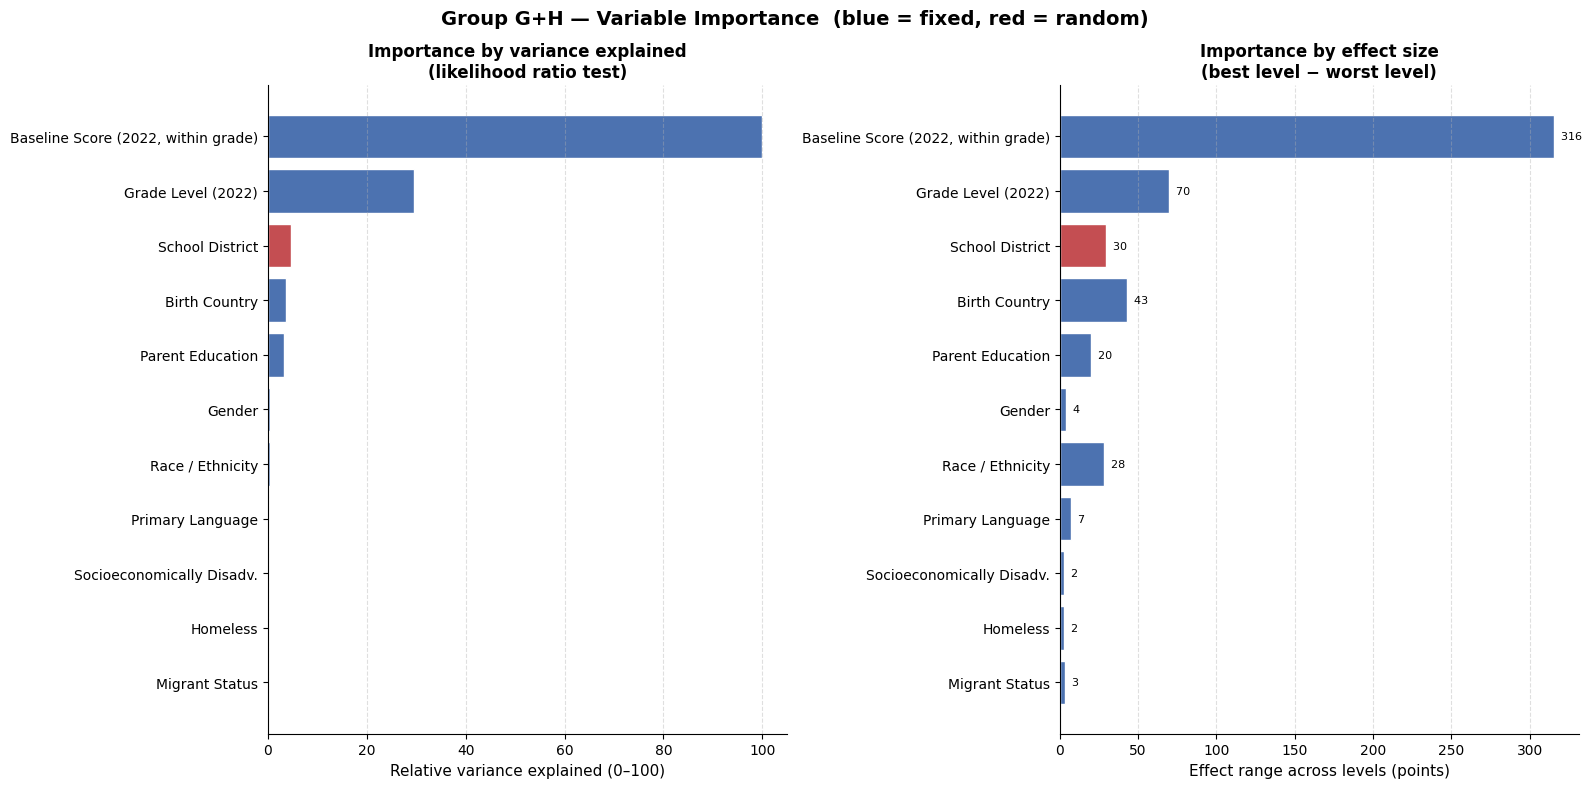

Saved: plots/group_gh_variable_importance.png


In [13]:
plot_df = imp.sort_values("Score_LRT", ascending=True)
colors = ["#C44E52" if t == "Random" else "#4C72B0" for t in plot_df["Type"]]

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].barh(plot_df["Label"], plot_df["Score_LRT"], color=colors, edgecolor="white")
axes[0].set_xlabel("Relative variance explained (0–100)", fontsize=11)
axes[0].set_title("Importance by variance explained\n(likelihood ratio test)",
                  fontsize=12, fontweight="bold")

axes[1].barh(plot_df["Label"], plot_df["EffectRange"], color=colors, edgecolor="white")
for i, (_, r) in enumerate(plot_df.iterrows()):
    axes[1].text(r["EffectRange"], i, f"  {r['EffectRange']:.0f}", va="center", fontsize=8)
axes[1].set_xlabel("Effect range across levels (points)", fontsize=11)
axes[1].set_title("Importance by effect size\n(best level − worst level)",
                  fontsize=12, fontweight="bold")

for ax in axes:
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(f"{group_label} — Variable Importance  (blue = fixed, red = random)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(f"plots/{group_short}_variable_importance.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: plots/{group_short}_variable_importance.png")

In [14]:
# --- Per-level detail for the top fixed effects, with readable labels ---

# Label maps applied at display time only; the model still uses raw codes.
LEVEL_LABELS = {
    "BirthCountry": country_labels,
    "ParentEd": PARENT_ED_LABELS,
}

def prettify(e, varname):
    """Map coded levels to full names for display. Preserves '(ref)' markers."""
    lut = LEVEL_LABELS.get(varname)
    if lut is None:
        return e
    e = e.copy()

    def relabel(lvl):
        lvl = str(lvl)
        # var_effects marks the reference row as "XX (ref)" — map the code, keep the marker
        if lvl.endswith(" (ref)"):
            code = lvl[:-6]
            return f"{lut.get(code, code)} (ref)"
        return lut.get(lvl, lvl)

    e["Level"] = e["Level"].map(relabel)
    return e


for v in imp[imp["Type"] == "Fixed"]["Variable"].head(6):
    e = var_effects(v)
    if e is None:
        continue
    e = prettify(e, v)
    e = e.sort_values("Effect", ascending=False)
    print(f"\n{'='*72}\n{readable.get(v, v)}\n{'='*72}")
    print(e.to_string(index=False))

    # Flag any level that didn't find a label
    lut = LEVEL_LABELS.get(v)
    if lut is not None:
        unmapped = [l for l in e["Level"]
                    if l not in lut.values() and not l.endswith(" (ref)")]
        if unmapped:
            print(f"\n  NOTE: no label found for {unmapped} — add to country_labels in Cell 0")

re_df = pd.DataFrame([
    {"District": d, "Effect": float(np.asarray(val).ravel()[0])}
    for d, val in full_model.random_effects.items()
])
re_df["N"] = re_df["District"].map(model_df["District"].value_counts())
re_df = re_df.sort_values("Effect", ascending=False)
print(f"\n{'='*72}\nSchool District (shrunken random effects)\n{'='*72}")
print(re_df.to_string(index=False))

unit = "points" if OUTCOME == "ScoreGain" else "SD units"
print(f"\nICC = {icc:.4f}  |  district SD = {np.sqrt(vb):.2f} {unit}")


Grade Level (2022)
   Level  Effect    P       N
      02    8.40 0.00  913.00
01 (ref)    0.00  NaN 1257.00
      03  -24.69 0.00  866.00
      KN  -26.72 0.00 3576.00
      04  -30.07 0.00  830.00
      05  -30.92 0.00  708.00
      06  -46.12 0.00  721.00
      09  -47.10 0.00 1957.00
      11  -50.54 0.00   85.00
      10  -53.02 0.00  541.00
      07  -60.78 0.00  751.00
      08  -61.29 0.00  695.00

Birth Country
            Level  Effect    P       N
          Ukraine   16.85 0.00  203.00
           Russia   14.41 0.00  426.00
            Haiti   13.80 0.06   99.00
          Vietnam   12.56 0.01  188.00
          Armenia    8.46 0.04  477.00
   Other (pooled)    5.89 0.02 1266.00
            China    2.84 0.52  235.00
Afghanistan (ref)    0.00  NaN 2111.00
         Colombia  -10.11 0.05  258.00
           Mexico  -10.83 0.00 1780.00
        Nicaragua  -11.67 0.02  319.00
      El Salvador  -17.74 0.00 1863.00
         Honduras  -23.61 0.00  971.00
          Unknown  -24.07 0.0

In [15]:
# ==============================================================
# BIRTH COUNTRY × LANGUAGE — CONFOUNDING DIAGNOSTIC
# ==============================================================
# Two variables that encode nearly the same information cannot be
# interpreted individually in a joint model. This cell measures how
# much they overlap before we fit anything.

from scipy.stats import chi2_contingency

ct = pd.crosstab(model_df["BirthCountry"], model_df["Language"])
print("CROSS-TABULATION: Birth Country × Language")
print("=" * 62)
print(ct.to_string())

# --- Percent of each country that is Spanish-speaking ---
pct = (ct.div(ct.sum(axis=1), axis=0) * 100).round(1)
print("\n\nPercent of each birth country by language:")
print("=" * 62)
print(pct.to_string())

# --- Cramér's V: 0 = independent, 1 = one perfectly predicts the other ---
chi2, p, dof, _ = chi2_contingency(ct)
n = ct.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

print("\n" + "=" * 62)
print(f"Cramér's V = {cramers_v:.4f}")
print(f"  chi2 = {chi2:,.1f}, dof = {dof}, p = {p:.2e}")
print("-" * 62)
if cramers_v > 0.7:
    print("SEVERE overlap — these variables encode nearly the same information.")
    print("Joint coefficients for BOTH are uninterpretable.")
elif cramers_v > 0.4:
    print("MODERATE overlap — joint coefficients are attenuated and unstable.")
else:
    print("MILD overlap — both can reasonably stay in the model.")
print("=" * 62)

# --- How cleanly does language partition the countries? ---
dominant = pct.idxmax(axis=1)
purity   = pct.max(axis=1)
print("\nDominant language per country (purity = % in that language):")
summary_ct = pd.DataFrame({
    "N": ct.sum(axis=1),
    "DominantLang": dominant,
    "Purity_%": purity.round(1),
}).sort_values("N", ascending=False)
print(summary_ct.to_string())

near_pure = (purity >= 95).sum()
print(f"\n{near_pure} of {len(purity)} countries are ≥95% one language.")
print("The higher this is, the more redundant the two variables are.")

CROSS-TABULATION: Birth Country × Language
Language      Non-Spanish  Spanish  Unknown
BirthCountry                               
AF                   2038        1       72
AM                    468        0        9
CN                    232        0        3
CO                      0      253        5
GT                    261     2246       31
HN                      2      955       14
HT                     74       25        0
MX                     15     1747       18
NI                      0      315        4
Other                1017      230       19
RU                    421        1        4
SV                      0     1836       27
UA                    201        0        2
UU                     25      136        5
VN                    187        0        1


Percent of each birth country by language:
Language      Non-Spanish  Spanish  Unknown
BirthCountry                               
AF                  96.50     0.00     3.40
AM                  98.10     0.

In [16]:
# ==============================================================
# FIT FOUR MODELS TO SEPARATE THE TWO EFFECTS
# ==============================================================
#   1. BOTH      — current specification
#   2. COUNTRY   — birth country only, language dropped
#   3. LANGUAGE  — language only, birth country dropped
#   4. NEITHER   — baseline for comparison
#
# ML (reml=False) is required: models with DIFFERENT fixed-effect
# sets have REML likelihoods that are not comparable.

specs = {
    "BOTH":     [t for t in fixed_cat],
    "COUNTRY":  [t for t in fixed_cat if t != "Language"],
    "LANGUAGE": [t for t in fixed_cat if t != "BirthCountry"],
    "NEITHER":  [t for t in fixed_cat if t not in ("BirthCountry", "Language")],
}

fits = {}
print("Fitting four models with ML...\n")
for name, terms in specs.items():
    f = build_formula(OUTCOME, BASELINE, terms)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = smf.mixedlm(f, data=model_df, groups="District").fit(
            reml=False, method="lbfgs", maxiter=2000)
    fits[name] = m
    print(f"  {name:<9} k={len(m.fe_params):>3}  logLik={m.llf:>12.2f}  "
          f"AIC={m.aic:>11.1f}  converged={m.converged}")

# --- Incremental contribution of each variable ---
print("\n" + "=" * 74)
print("INCREMENTAL CONTRIBUTION (likelihood ratio tests)")
print("=" * 74)

comparisons = [
    ("Language added to a model that already has Country",  "COUNTRY",  "BOTH"),
    ("Country added to a model that already has Language",  "LANGUAGE", "BOTH"),
    ("Country alone (vs neither)",                          "NEITHER",  "COUNTRY"),
    ("Language alone (vs neither)",                         "NEITHER",  "LANGUAGE"),
]

lrt_rows = []
for label, reduced, full in comparisons:
    lr  = 2 * (fits[full].llf - fits[reduced].llf)
    dfd = len(fits[full].fe_params) - len(fits[reduced].fe_params)
    pv  = sps.chi2.sf(lr, dfd) if dfd > 0 else np.nan
    lrt_rows.append({"Comparison": label, "chi2": lr, "df": dfd, "p": pv})
    print(f"\n{label}")
    print(f"   chi2 = {lr:>9.2f}   df = {dfd:>3}   p = {pv:.3e}"
          f"   {'SIGNIFICANT' if pv < 0.05 else 'not significant'}")

print("\n" + "=" * 74)
disentangle = pd.DataFrame(lrt_rows)

Fitting four models with ML...

  BOTH      k= 46  logLik=   -70400.04  AIC=   140896.1  converged=True
  COUNTRY   k= 44  logLik=   -70403.33  AIC=   140898.7  converged=True
  LANGUAGE  k= 32  logLik=   -70488.87  AIC=   141045.7  converged=True
  NEITHER   k= 30  logLik=   -70489.19  AIC=   141042.4  converged=True

INCREMENTAL CONTRIBUTION (likelihood ratio tests)

Language added to a model that already has Country
   chi2 =      6.59   df =   2   p = 3.714e-02   SIGNIFICANT

Country added to a model that already has Language
   chi2 =    177.67   df =  14   p = 1.925e-30   SIGNIFICANT

Country alone (vs neither)
   chi2 =    171.72   df =  14   p = 3.075e-29   SIGNIFICANT

Language alone (vs neither)
   chi2 =      0.64   df =   2   p = 7.262e-01   not significant



In [17]:
# ==============================================================
# COEFFICIENT SHIFT: joint model vs solo model
# ==============================================================
# A coefficient that changes substantially when the other variable
# is removed was absorbing that variable's effect.

def extract(model, prefix):
    p  = model.fe_params
    se = model.bse_fe
    pv = model.pvalues[p.index]
    m  = p.index.str.startswith(prefix)
    return pd.DataFrame({
        "Term":   p.index[m].str.extract(r"\[T\.(.+?)\]")[0].values,
        "Coef":   p[m].values,
        "SE":     se[m].values,
        "P":      pv[m].values,
    })

# --- Birth country ---
bc_both = extract(fits["BOTH"],    "C(BirthCountry)").set_index("Term")
bc_solo = extract(fits["COUNTRY"], "C(BirthCountry)").set_index("Term")

bc = bc_both.join(bc_solo, lsuffix="_joint", rsuffix="_solo")
bc["Shift"]    = bc["Coef_solo"] - bc["Coef_joint"]
bc["Shift_SE"] = bc["Shift"] / bc["SE_joint"]      # shift in standard-error units
bc["N"]        = model_df["BirthCountry"].value_counts()
bc = bc.sort_values("Coef_solo")

print("=" * 96)
print("BIRTH COUNTRY — coefficients with and without Language in the model")
print("=" * 96)
print(bc[["N", "Coef_joint", "P_joint", "Coef_solo", "P_solo", "Shift", "Shift_SE"]]
      .round(3).to_string())

# --- Language ---
lg_both = extract(fits["BOTH"],     "C(Language)").set_index("Term")
lg_solo = extract(fits["LANGUAGE"], "C(Language)").set_index("Term")

lg = lg_both.join(lg_solo, lsuffix="_joint", rsuffix="_solo")
lg["Shift"]    = lg["Coef_solo"] - lg["Coef_joint"]
lg["Shift_SE"] = lg["Shift"] / lg["SE_joint"]
lg["N"]        = model_df["Language"].value_counts()

print("\n" + "=" * 96)
print("LANGUAGE — coefficients with and without Birth Country in the model")
print("=" * 96)
print(lg[["N", "Coef_joint", "P_joint", "Coef_solo", "P_solo", "Shift", "Shift_SE"]]
      .round(3).to_string())

# --- Standard error inflation from collinearity ---
print("\n" + "=" * 96)
print("STANDARD ERROR INFLATION (joint ÷ solo — how much precision collinearity costs)")
print("=" * 96)
bc_infl = (bc["SE_joint"] / bc["SE_solo"]).sort_values(ascending=False)
print("\nBirth country:")
print(bc_infl.round(3).to_string())
print(f"\n  median inflation: {bc_infl.median():.3f}x   max: {bc_infl.max():.3f}x")

lg_infl = (lg["SE_joint"] / lg["SE_solo"])
print("\nLanguage:")
print(lg_infl.round(3).to_string())
print(f"\n  median inflation: {lg_infl.median():.3f}x   max: {lg_infl.max():.3f}x")

BIRTH COUNTRY — coefficients with and without Language in the model
          N  Coef_joint  P_joint  Coef_solo  P_solo  Shift  Shift_SE
Term                                                                
GT     2538      -25.74     0.00     -22.40    0.00   3.35      0.89
UU      166      -24.05     0.00     -20.90    0.00   3.15      0.57
HN      971      -23.60     0.00     -19.59    0.00   4.01      0.98
SV     1863      -17.71     0.00     -13.74    0.00   3.98      1.02
NI      319      -11.66     0.02      -7.66    0.09   4.00      0.83
MX     1780      -10.82     0.01      -6.92    0.05   3.90      1.01
CO      258      -10.09     0.05      -6.20    0.20   3.88      0.76
CN      235        2.84     0.52       2.96    0.50   0.11      0.03
Other  1266        5.91     0.02       6.54    0.01   0.63      0.25
AM      477        8.58     0.04       8.45    0.04  -0.13     -0.03
VN      188       12.63     0.01      12.60    0.01  -0.03     -0.01
RU      426       14.47     0.00   

In [18]:
# ==============================================================
# VERDICT
# ==============================================================
lang_given_country = disentangle.iloc[0]
country_given_lang = disentangle.iloc[1]
country_alone      = disentangle.iloc[2]
language_alone     = disentangle.iloc[3]

print("=" * 74)
print("DISENTANGLING BIRTH COUNTRY AND LANGUAGE — VERDICT")
print("=" * 74)
print(f"\nOverlap (Cramér's V):            {cramers_v:.3f}")
print(f"Country alone explains:          chi2 = {country_alone['chi2']:>8.1f} "
      f"(df {int(country_alone['df'])})")
print(f"Language alone explains:         chi2 = {language_alone['chi2']:>8.1f} "
      f"(df {int(language_alone['df'])})")
print(f"Country adds to Language:        chi2 = {country_given_lang['chi2']:>8.1f} "
      f"(p = {country_given_lang['p']:.2e})")
print(f"Language adds to Country:        chi2 = {lang_given_country['chi2']:>8.1f} "
      f"(p = {lang_given_country['p']:.2e})")

print(f"\nAIC — BOTH: {fits['BOTH'].aic:,.1f}   COUNTRY: {fits['COUNTRY'].aic:,.1f}   "
      f"LANGUAGE: {fits['LANGUAGE'].aic:,.1f}   NEITHER: {fits['NEITHER'].aic:,.1f}")
best = min(fits, key=lambda k: fits[k].aic)
print(f"Best by AIC: {best}")

print("\n" + "-" * 74)
if country_given_lang["p"] < 0.05 and lang_given_country["p"] >= 0.05:
    print("RECOMMENDATION: keep BIRTH COUNTRY, drop LANGUAGE.")
    print("Country adds real information beyond language; language adds none")
    print("beyond country. The positive Spanish coefficient in the joint model")
    print("was a residual artifact, not a finding.")
elif lang_given_country["p"] < 0.05 and country_given_lang["p"] >= 0.05:
    print("RECOMMENDATION: keep LANGUAGE, drop BIRTH COUNTRY.")
elif country_given_lang["p"] < 0.05 and lang_given_country["p"] < 0.05:
    print("RECOMMENDATION: both contribute independently — keep both, but")
    print("report them as a joint block rather than interpreting individual")
    print("coefficients, given the collinearity.")
else:
    print("RECOMMENDATION: neither adds much once the other is present.")
    print("Keep whichever is more interpretable for your audience.")
print("-" * 74)
print("\nReport SOLO coefficients for whichever variable you keep —")
print("the joint estimates are contaminated by the other.")
print("=" * 74)

DISENTANGLING BIRTH COUNTRY AND LANGUAGE — VERDICT

Overlap (Cramér's V):            0.644
Country alone explains:          chi2 =    171.7 (df 14)
Language alone explains:         chi2 =      0.6 (df 2)
Country adds to Language:        chi2 =    177.7 (p = 1.92e-30)
Language adds to Country:        chi2 =      6.6 (p = 3.71e-02)

AIC — BOTH: 140,896.1   COUNTRY: 140,898.7   LANGUAGE: 141,045.7   NEITHER: 141,042.4
Best by AIC: BOTH

--------------------------------------------------------------------------
RECOMMENDATION: both contribute independently — keep both, but
report them as a joint block rather than interpreting individual
coefficients, given the collinearity.
--------------------------------------------------------------------------

Report SOLO coefficients for whichever variable you keep —
the joint estimates are contaminated by the other.


# Group G+H Mixed-Effects Analysis: Results Summary (Scale-Score Points)

**Outcome:** Summative 2024 minus Summative 2022, in ELPAC Overall Scale Score points (`ScoreGain`)
**Baseline control:** each student's 2022 score, centered within grade (`S1_wg`)
**Model:** Linear mixed model with student characteristics as fixed effects and district as a random intercept
**Sample:** 12,900 of 12,918 students (99.9%) in 23 districts
**Average gain:** 103.5 points over two years (SD 73.1; range −235 to +472)

---

## Executive summary

1. **The model and the descriptive figures agree.** With both expressed in scale-score points, the model's grade ranking matches the observed ranking almost exactly (rank agreement 0.96) and follows the same order as the Figure 15 learning-rate chart. The earlier disagreement came from expressing the model in grade-standardized SD units and reporting it against a Grade 1 reference.

2. **Grade level is by far the strongest predictor of growth** (likelihood ratio χ² = 1,404, more than six times the next characteristic). Gains fall steadily with grade: students who began in Grades 2 and 1 gained the most (143 and 135 points adjusted), and students who began in Grades 7 and 8 gained the least (about 73 points).

3. **Kindergarten is not an outlier.** Kindergarten ranks 4th of 12 grades in both observed and adjusted gain (108 points in each) and sits close to the cohort average. Other characteristics explain essentially nothing about its position.

4. **Adjustment matters mainly for high school.** Grades 9, 10, and 11 rise 6 to 10 points after adjustment, while every other grade changes by 4 points or less. The slowest adjusted growth belongs to Grades 7 and 8.

5. **Districts differ in a real but modest way.** District accounts for 2.7% of the variation in growth, and the adjusted spread from the strongest to the weakest district is about 30 points. Unadjusted district rankings largely reflect grade mix: a district's expected gain correlates +0.69 with its share of K to 5 students.

6. **Country of birth shows the largest demographic gap** (about 43 points adjusted). Central American and Mexican origin groups grow least and Eastern European origin groups most. This ordering is identical whether measured in points or SD units.

7. **Parent education shows a clear step pattern.** Relative to students whose parents did not finish high school, students whose parents graduated high school gained about 10 points more, and students whose parents had any postsecondary education gained about 20 points more. The three postsecondary levels are indistinguishable. Students whose parents' education is declined or unknown grew like those whose parents did not finish high school.

8. **Socioeconomic disadvantage is no longer a significant independent predictor** once parent education is measured correctly (p = 0.062). The 13-point observed gap shrinks to 2.5 points after adjustment, largely because "parent did not graduate from high school" is one of the criteria for the disadvantaged designation, so the two measures overlap.

9. **Several large observed gaps shrink or reverse after adjustment.** The 21-point White versus Hispanic/Latino gap falls to about 5 points and is not significant. The 14-point disadvantage for Spanish speakers reverses once country of birth is accounted for.

10. **Only grade is sensitive to the choice of metric.** Grade rankings agree poorly between points and SD units (rank correlation 0.31), while every other characteristic agrees closely (0.82 to 1.00).

---

## 1. Specification

The Summative ELPAC is reported on a vertical scale designed for comparing growth across grade levels, so scale-score points are a legitimate common metric and match the units of the descriptive figures. The baseline score is centered within each grade so that it controls for where a student stood relative to grade peers without absorbing real differences between grades.

**Observed** values are each group's actual mean gain. **Adjusted** values are the average gain the model predicts if every student in the cohort belonged to that group, with all other characteristics, including each student's own district, left unchanged. Both are in points on the same baseline, so they can be compared directly, and neither depends on a reference category.

---

## 2. Model fit and variance

| Quantity | Value |
|---|---|
| Converged | Yes (REML) |
| Between-district variance | 88.46 (SD 9.41 points) |
| Within-district variance | 3,218.03 (SD 56.73 points) |
| Intraclass correlation | 0.0268 (2.68% of variation between districts) |
| District likelihood ratio test | χ² = 222.7, p = 1.1 × 10⁻⁵⁰ (halved for boundary; conclusion unchanged unhalved) |

---

## 3. Variable importance

Likelihood ratio tests from dropping each characteristic in turn (ML fits). The 2022 baseline (χ² = 4,756) is omitted because the outcome is constructed by subtracting it.

| Rank | Characteristic | χ² | Raw p | Bonferroni | BH-FDR |
|---|---|---|---|---|---|
| 1 | Grade level | 1,404.5 | < 0.001 | ✓ | ✓ |
| 2 | School district | 222.7 | < 0.001 | ✓ | ✓ |
| 3 | Country of birth | 177.7 | < 0.001 | ✓ | ✓ |
| 4 | Parent education | 157.0 | < 0.001 | ✓ | ✓ |
| 5 | Gender | 16.9 | < 0.001 | ✓ | ✓ |
| 6 | Race and ethnicity | 16.7 | 0.020 | ✗ | ✓ |
| 7 | Primary language | 6.6 | 0.037 | ✗ | ✗ |
| 8 | Socioeconomically disadvantaged | 3.5 | 0.062 | ✗ | ✗ |
| 9 | Homeless program | 1.8 | 0.177 | ✗ | ✗ |
| 10 | Migrant status | 0.3 | 0.576 | ✗ | ✗ |

Seven characteristics are significant at p < 0.05. Five survive Bonferroni correction: grade, district, country of birth, parent education, and gender. Race and ethnicity survives the less strict BH-FDR correction only and should be treated as suggestive. Primary language fails both corrections.

---

## 4. Grade level

Rank agreement between observed and adjusted: **0.96.** All coefficients p ≤ 0.001.

| Grade (2022) | Students | Observed gain | Adjusted gain | Observed rank | Adjusted rank | Coefficient vs Grade 1 |
|---|---|---|---|---|---|---|
| Grade 2 | 913 | 145.3 | 143.1 | 1 | 1 | +8.4 |
| Grade 1 | 1,257 | 136.4 | 134.7 | 2 | 2 | 0 (reference) |
| Grade 3 | 866 | 113.7 | 110.0 | 3 | 3 | −24.7 |
| Kindergarten | 3,576 | 108.3 | 108.0 | 4 | 4 | −26.7 |
| Grade 4 | 830 | 108.1 | 104.6 | 5 | 5 | −30.1 |
| Grade 5 | 708 | 105.6 | 103.8 | 6 | 6 | −30.9 |
| Grade 6 | 721 | 90.7 | 88.6 | 7 | 7 | −46.1 |
| Grade 9 | 1,957 | 81.8 | 87.6 | 8 | 8 | −47.1 |
| Grade 11 | 85 | 74.1 | 84.2 | 12 | 9 | −50.5 |
| Grade 10 | 541 | 75.6 | 81.7 | 9 | 10 | −53.0 |
| Grade 7 | 751 | 75.1 | 73.9 | 10 | 11 | −60.8 |
| Grade 8 | 695 | 74.2 | 73.4 | 11 | 12 | −61.3 |

Growth declines steadily from the early grades to the middle grades. Students who began in Grades 1 and 2 gained nearly twice as many points as students who began in Grades 7 and 8; the adjusted spread from Grade 2 to Grade 8 is about 70 points.

**Kindergarten** gained 108 points both observed and adjusted, 4th of 12 grades, within 5 points of the cohort average.

**High school** is where adjustment matters. Grade 9 rises 5.8 points, Grade 10 rises 6.1, and Grade 11 rises 10.1 after adjustment, while all other grades change by 4 points or less. Part of the high school grades' lower observed growth is explained by their students' backgrounds rather than by grade.

---

## 5. Country of birth

Rank agreement between observed and adjusted: **0.73.** Coefficients are relative to Afghanistan.

| Country | Students | Observed gain | Adjusted gain | Observed rank | Adjusted rank | Coefficient | p |
|---|---|---|---|---|---|---|---|
| Ukraine | 203 | 130.9 | 130.1 | 2 | 1 | +16.9 | < 0.001 |
| Russia | 426 | 140.0 | 127.6 | 1 | 2 | +14.4 | < 0.001 |
| Haiti | 99 | 110.5 | 127.0 | 7 | 3 | +13.8 | 0.056 |
| Vietnam | 188 | 105.5 | 125.8 | 8 | 4 | +12.6 | 0.012 |
| Armenia | 477 | 118.3 | 121.7 | 4 | 5 | +8.5 | 0.040 |
| Other (pooled) | 1,266 | 103.9 | 119.1 | 10 | 6 | +5.9 | 0.020 |
| China | 235 | 94.1 | 116.1 | 12 | 7 | +2.8 | 0.516 |
| Afghanistan | 2,111 | 117.3 | 113.2 | 5 | 8 | 0 (reference) | |
| Colombia | 258 | 120.4 | 103.1 | 3 | 9 | −10.1 | 0.047 |
| Mexico | 1,780 | 104.3 | 102.4 | 9 | 10 | −10.8 | 0.005 |
| Nicaragua | 319 | 112.2 | 101.5 | 6 | 11 | −11.7 | 0.016 |
| El Salvador | 1,863 | 98.1 | 95.5 | 11 | 12 | −17.7 | < 0.001 |
| Honduras | 971 | 90.8 | 89.6 | 13 | 13 | −23.6 | < 0.001 |
| Unknown | 166 | 77.7 | 89.1 | 15 | 14 | −24.1 | < 0.001 |
| Guatemala | 2,538 | 88.3 | 87.5 | 14 | 15 | −25.8 | < 0.001 |

The adjusted spread from Ukraine to Guatemala is about 43 points, the largest demographic gap in the study. Every Central American and Mexican origin group falls in the bottom seven; Eastern European origin groups lead. Students from Guatemala, the largest origin group, grew least.

Several countries move substantially between observed and adjusted, mostly reflecting grade mix: Colombia (3rd to 9th) and Nicaragua (6th to 11th) fall, while China (12th to 7th), Vietnam (8th to 4th), and Haiti (7th to 3rd) rise. Haiti and China are not individually significant.

---

## 6. School district

| District | Students | % in K to 5 | Most common birth country | Observed | Expected given its students | Observed minus expected | District effect (shrunken) | Observed rank | Adjusted rank |
|---|---|---|---|---|---|---|---|---|---|
| LA County Office of Education | 42 | 28.6 | Guatemala | 94.5 | 69.4 | +25.1 | +13.5 | 15 | 1 |
| Glendale Unified | 523 | 68.1 | Armenia | 125.6 | 111.6 | +14.0 | +13.1 | 2 | 2 |
| Los Angeles Unified | 5,397 | 57.8 | Guatemala | 102.8 | 90.6 | +12.2 | +12.1 | 11 | 3 |
| Mendota Unified | 117 | 68.4 | El Salvador | 103.2 | 90.4 | +12.8 | +9.7 | 10 | 4 |
| Mt. Diablo Unified | 305 | 71.8 | Afghanistan | 129.5 | 121.7 | +7.8 | +6.9 | 1 | 5 |
| San Diego Unified | 817 | 66.2 | Afghanistan | 116.5 | 109.4 | +7.1 | +6.8 | 4 | 6 |
| San Rafael City Elementary | 128 | 80.5 | Guatemala | 98.1 | 90.4 | +7.8 | +6.1 | 13 | 7 |
| Garden Grove Unified | 227 | 67.4 | Vietnam | 104.6 | 97.6 | +7.0 | +6.0 | 8 | 8 |
| Modesto City High | 27 | 0.0 | Afghanistan | 84.4 | 76.4 | +7.9 | +3.4 | 20 | 9 |
| Cajon Valley Union | 496 | 81.5 | Afghanistan | 119.2 | 119.3 | −0.2 | −0.2 | 3 | 10 |
| San Juan Unified | 915 | 73.3 | Afghanistan | 113.4 | 113.8 | −0.4 | −0.4 | 5 | 11 |
| Fresno Unified | 231 | 72.3 | Mexico | 103.9 | 105.3 | −1.4 | −1.2 | 9 | 12 |
| Modesto City Elementary | 183 | 85.8 | Mexico | 106.6 | 108.2 | −1.7 | −1.4 | 7 | 13 |
| Elk Grove Unified | 379 | 72.3 | Afghanistan | 95.8 | 98.4 | −2.7 | −2.4 | 14 | 14 |
| Alvord Unified | 80 | 68.8 | Mexico | 93.8 | 97.4 | −3.6 | −2.5 | 16 | 15 |
| Santa Ana Unified | 269 | 67.3 | Mexico | 91.2 | 94.0 | −2.8 | −2.5 | 17 | 16 |
| Hayward Unified | 304 | 65.5 | El Salvador | 102.7 | 106.6 | −3.9 | −3.4 | 12 | 17 |
| San Francisco Unified | 441 | 45.8 | China | 73.5 | 79.1 | −5.6 | −5.2 | 21 | 18 |
| San Rafael City High | 66 | 0.0 | Guatemala | 64.0 | 72.3 | −8.3 | −5.4 | 23 | 19 |
| Oakland Unified | 762 | 65.1 | Guatemala | 86.0 | 96.2 | −10.2 | −9.7 | 19 | 20 |
| West Contra Costa Unified | 409 | 70.9 | Guatemala | 87.0 | 101.6 | −14.6 | −13.4 | 18 | 21 |
| Twin Rivers Unified | 707 | 66.2 | Afghanistan | 108.1 | 122.6 | −14.5 | −13.8 | 6 | 22 |
| Grossmont Union High | 75 | 0.0 | Afghanistan | 67.7 | 91.7 | −23.9 | −16.1 | 22 | 23 |

**How to read it.** "Expected" is what a district's own students would gain in an average district, given their grades, countries of birth, parent education, and other characteristics. The district's contribution is the gap between observed and expected; the shrunken district effect is that same gap after the model moderates estimates for small districts.

**Grade mix drives the unadjusted ranking.** A district's expected gain correlates **+0.69** with its share of K to 5 students. High-school-only districts (Grossmont Union High, San Rafael City High, Modesto City High) have low observed gains largely because their students are older.

**Biggest movers:**

- **Twin Rivers Unified** gained 108 points (6th observed), but its students were expected to gain 123, giving an adjusted effect of −13.8 (22nd).
- **Cajon Valley Union** (81.5% K to 5) gained 119 points (3rd observed), exactly what its young students were expected to gain (10th adjusted).
- **Los Angeles County Office of Education** gained 94.5 points against an expectation of 69.4 (28.6% K to 5, mostly from Guatemala) and ranks 1st adjusted. With only 42 students, its effect has been shrunk by roughly half, and its top position should be stated with caution.
- **Modesto City High** rises from 20th to 9th for the same reason, on only 27 students.

The adjusted range runs from Los Angeles County Office of Education (+13.5) to Grossmont Union High (−16.1), about 30 points. Among districts with at least 100 students, Glendale Unified (+13.1) and Los Angeles Unified (+12.1) lead. District accounts for 2.7% of the variation in growth; the remaining 97.3% lies between students within the same district.

---

## 7. Parent education

Rank agreement between observed and adjusted: **0.75.** Coefficients are relative to "Not a high school graduate."

| Parent/guardian education | Students | Observed gain | Adjusted gain | Coefficient | p |
|---|---|---|---|---|---|
| Graduate degree or higher | 800 | 113.0 | 116.5 | +20.0 | < 0.001 |
| College graduate | 1,168 | 114.7 | 116.2 | +19.7 | < 0.001 |
| Some college or associate degree | 688 | 116.9 | 116.1 | +19.6 | < 0.001 |
| High school graduate | 2,591 | 105.5 | 106.4 | +9.9 | < 0.001 |
| Not recorded | 57 | 88.5 | 99.1 | +2.5 | 0.765 |
| Declined to state or unknown | 4,728 | 99.6 | 99.0 | +2.5 | 0.092 |
| Not a high school graduate | 2,868 | 98.0 | 96.5 | 0 (reference) | |

The pattern is a clear step: about **10 points** from not finishing high school to finishing it, and about **20 points** to any postsecondary education, after which additional education adds nothing. Students in the "declined to state or unknown" group, which CALPADS also uses when a parent's education is not known, grew at the same rate as students whose parents did not finish high school. The effect holds after controlling for socioeconomic status, country of birth, grade, and district.

---

## 8. Other characteristics

**Race and ethnicity** (χ² = 16.7, p = 0.020; fails Bonferroni). Coefficients are relative to Hispanic/Latino (8,002 students).

| Group | Students | Observed | Adjusted | Coefficient | p |
|---|---|---|---|---|---|
| Two or More Races | 91 | 145.1 | 116.4 | +14.8 | 0.029 |
| Asian | 1,923 | 111.5 | 108.4 | +6.8 | 0.048 |
| Not Reported | 475 | 113.0 | 106.3 | +4.7 | 0.212 |
| White | 2,107 | 118.4 | 106.2 | +4.6 | 0.162 |
| Filipino | 78 | 78.1 | 105.9 | +4.3 | 0.547 |
| Pacific Islander | 47 | 101.7 | 105.5 | +3.9 | 0.659 |
| Hispanic/Latino | 8,002 | 97.1 | 101.6 | 0 (reference) | |
| Black | 177 | 91.2 | 88.4 | −13.2 | 0.020 |

The 21-point observed gap between White and Hispanic/Latino students shrinks to about 5 points after adjustment and is not significant; country of birth accounts for most of it.

**Gender.** Female 105.4 observed and 105.7 adjusted; male 101.8 and 101.6. Males gained 4.1 points less (p < 0.001), a small effect consistent across every version of the analysis.

**Socioeconomically disadvantaged.** Not disadvantaged 113.7 observed and 105.4 adjusted; disadvantaged 100.4 and 102.9. The 13.3-point observed gap shrinks to 2.5 points and is **not significant** (p = 0.062). California's disadvantaged designation includes students whose parents did not graduate from high school, so with parent education correctly measured, the two characteristics overlap and parent education carries the effect.

**Primary language.** Spanish speakers 97.9 observed and 106.2 adjusted; non-Spanish speakers 111.9 and 99.3. The observed disadvantage reverses after adjustment because country of birth explains it; see Section 9.

**Homeless program** (−2.4, p = 0.173) and **migrant status** (−3.1, p = 0.566) show no detectable effect.

---

## 9. Birth country and primary language

The two variables overlap heavily (Cramér's V = 0.644; 11 of 15 countries are at least 95% one language).

| Test | χ² | df | p |
|---|---|---|---|
| Country alone | 171.7 | 14 | < 0.001 |
| Language alone | 0.6 | 2 | 0.726 |
| Country added to language | 177.7 | 14 | < 0.001 |
| Language added to country | 6.6 | 2 | 0.037 |

Language alone predicts nothing. The Spanish coefficient is +6.9 with country in the model and −0.4 (p = 0.87) without it, a shift of 2.7 standard errors. AIC slightly favors keeping both variables (140,896.1 versus 140,898.7 for country only). The Spanish coefficient is therefore a **within-country** contrast: in countries with mixed language populations, mainly Guatemala (88.5% Spanish, 10.3% other, largely indigenous languages), Haiti, and the pooled Other group, students whose primary language is not Spanish gained less than Spanish-speaking students from the same country. It should not be reported as a general Spanish-speaker effect, and it does not survive correction for multiple comparisons.

---

## 10. Robustness: points versus SD units

The same model was refit with grade-standardized SD units (`ZGain_fixed`, baseline `Z1_fixed`) and the adjusted rankings compared.

| Characteristic | Levels | Rank agreement | Levels moving 3+ places |
|---|---|---|---|
| Grade | 12 | 0.31 | Grade 2 (1 to 6); Grade 1 (2 to 8); Kindergarten (4 to 10); Grade 4 (5 to 1); Grade 5 (6 to 3); Grade 9 (8 to 2); Grade 11 (9 to 4) |
| Parent education | 7 | 0.82 | none |
| Race and ethnicity | 8 | 0.98 | none |
| Country of birth | 15 | 1.00 | none |
| Primary language | 3 | 1.00 | none |
| School district | 23 | 0.99 | (see Section 6) |

**Grade is the only metric-sensitive result.** In points, early grades grow most; in SD units, Grades 4 and 9 lead, because early grades have much wider score spreads (2022 SD of 78 to 87 points in K to 2, versus 48 to 63 in Grades 7 to 11). Findings that hold under both metrics: Grades 7 and 8 are among the slowest-growing grades, and the country, district, parent education, race, and language results are unchanged.

---

## 11. Changes from earlier runs

| Finding | SD-unit model | Points model, merged parent education | Points model, corrected parent education (current) |
|---|---|---|---|
| Fastest-growing grades | Grades 4 and 9 | Grades 2 and 1 | Grades 2 and 1 |
| Kindergarten | 10th of 12; −0.18 SD vs Grade 1 | 4th of 12 | 4th of 12; 108 points |
| Parent education | Reversed labels | Reversed labels; HS graduates merged with non-graduates | Step pattern: +10 for HS, +20 for any postsecondary |
| Parent education χ² | 96.2 | 120.7 | 157.0 |
| Socioeconomic disadvantage | Significant (−0.07 SD) | Significant (−4.4 points) | Not significant (−2.5 points, p = 0.062) |
| Characteristics surviving Bonferroni (excluding baseline) | 6 | 6 | 5 |
| ICC | 2.31% | 2.52% | 2.68% |
| Top adjusted district | Glendale Unified | Glendale Unified | LA County Office of Education (42 students); Glendale Unified among larger districts |

Report text based on earlier runs should be revised, in particular any statement that upper elementary students grow fastest, that kindergarten is well below average, that socioeconomic disadvantage independently predicts growth, or that higher parent education is associated with lower growth.

---

## 12. Limitations

- **Associations, not causes.** Students were not randomly assigned to grades, districts, or circumstances.
- **Unmeasured factors** such as attendance, program model, instructional minutes, prior schooling, and services received are not in the data.
- **Demographics are measured once**, in 2021-22.
- **The cohort is selective:** students with three consecutive years of records. Students who moved, stopped testing, or were reclassified are not represented.
- **Cross-grade point comparisons** rely on the ELPAC vertical scale; CDE advises caution when comparing nonadjacent grade levels.
- **Small districts** are estimated with less precision even after shrinkage; the top-ranked district has 42 students.
- **Statistical significance is not practical significance.** With nearly 13,000 students, effects of 4 points are detectable.

In [19]:
# --- What are the actual RaceEthnicity codes? ---
print("RaceEthnicity in the FULL enrollment file (not just G+H):")
print(enrollment["RaceEthnicity"].value_counts(dropna=False).to_string())

print("\n\nCross-check against the component race fields:")
xtab = (
    enrollment[["RaceEthnicity", "StudentHispanicEthnicityIndicator", "StudentRace1Code"]]
    .astype(str).apply(lambda c: c.str.strip())
    .value_counts()
    .reset_index(name="N")
    .sort_values(["RaceEthnicity", "N"], ascending=[True, False])
)
for code in sorted(xtab["RaceEthnicity"].unique()):
    sub = xtab[xtab["RaceEthnicity"] == code].head(3)
    print(f"\n  RaceEthnicity = '{code}'  (total {sub['N'].sum():,}+)")
    for _, r in sub.iterrows():
        print(f"    Hispanic={r['StudentHispanicEthnicityIndicator']:<6} "
              f"Race1={r['StudentRace1Code']:<6} n={r['N']:,}")

RaceEthnicity in the FULL enrollment file (not just G+H):
RaceEthnicity
H    914672
W    224835
A    127842
B    122586
T     57180
F     32290
D     28469
P      7835
I      3909


Cross-check against the component race fields:

  RaceEthnicity = 'A'  (total 84,155+)
    Hispanic=N      Race1=201.0  n=30,882
    Hispanic=N      Race1=204.0  n=27,639
    Hispanic=N      Race1=299.0  n=25,634

  RaceEthnicity = 'B'  (total 122,273+)
    Hispanic=N      Race1=600.0  n=122,273

  RaceEthnicity = 'F'  (total 30,879+)
    Hispanic=N      Race1=400.0  n=29,415
    Hispanic=N      Race1=201.0  n=992
    Hispanic=N      Race1=299.0  n=472

  RaceEthnicity = 'H'  (total 630,628+)
    Hispanic=Y      Race1=700.0  n=532,608
    Hispanic=Y      Race1=100.0  n=76,395
    Hispanic=Y      Race1=600.0  n=21,625

  RaceEthnicity = 'I'  (total 3,866+)
    Hispanic=N      Race1=100.0  n=3,866

  RaceEthnicity = 'P'  (total 7,359+)
    Hispanic=N      Race1=399.0  n=5,009
    Hispanic=N      Race1=303.0  

In [20]:
# =============================================================================
# Observed vs. adjusted growth, on one metric
# For: Group_G_H_mixed_effects_HLM.ipynb
#
# Purpose: make the HLM tables and the descriptive figures use the SAME units
# (vertically scaled ELPAC scale-score points), and present each characteristic
# as "observed gain" next to "adjusted gain" instead of contrasts against a
# reference category.
#
# SETUP (two small edits to existing cells, then Restart and Run All):
#
#   Cell 0, change the outcome switch to:
#       OUTCOME  = "ScoreGain"
#       BASELINE = "S1_wg"
#
#   Cell 6, add this line right after work["Grade"] is created:
#       work["S1_wg"] = work["Summ1Score"] - work.groupby("Grade")["Summ1Score"].transform("mean")
#
#   Why S1_wg: the starting score is centered WITHIN each grade, so the
#   baseline control adjusts for where a student stands relative to grade
#   peers without absorbing the real differences between grades. The earlier
#   raw-point model centered on the cohort mean, and because older grades
#   start higher, its baseline term soaked up much of the grade effect.
#
# After the rerun, every existing table (6 through 10) is in points.
# Then paste the four cells below after Cell 8 (the model fit).
# =============================================================================

In [21]:
# %% [Cell A] Observed vs adjusted gain for every characteristic
import numpy as np
import pandas as pd
import warnings
import statsmodels.formula.api as smf

assert OUTCOME == "ScoreGain" and BASELINE == "S1_wg", "Make the Cell 0 edit first (see header)."

GRADE_LABELS = {"KN": "Kindergarten", **{f"{g:02d}": f"Grade {g}" for g in range(1, 13)}}

RACE_DISPLAY = {"Hispanic_Latino": "Hispanic/Latino", "TwoOrMore": "Two or More Races",
                "NotReported": "Not Reported", "PacificIslander": "Pacific Islander"}
YES_NO = {"Y": "Yes", "N": "No"}
GENDER_DISPLAY = {"F": "Female", "M": "Male"}

def pretty(var, lvl):
    lut = {"Grade": GRADE_LABELS, "BirthCountry": country_labels,
           "ParentEd": PARENT_ED_LABELS, "Race": RACE_DISPLAY,
           "Gender": GENDER_DISPLAY, "SED": YES_NO,
           "Migrant": YES_NO, "Homeless": YES_NO}.get(var, {})
    return lut.get(lvl, lvl)

def observed_vs_adjusted(model, data, var, outcome):
    """
    Observed: the group's actual mean gain.
    Adjusted: the average predicted gain if every student in the cohort belonged
              to this group, with everything else about them unchanged
              (g-computation), including each student's own district effect.
              Same units and same baseline as Observed; no reference category.
    """
    obs = data.groupby(var)[outcome].agg(Students="size", Observed="mean")
    re_map = {d: float(np.asarray(v).ravel()[0]) for d, v in model.random_effects.items()}
    blup = data["District"].map(re_map).fillna(0).to_numpy()
    adj = {}
    for lvl in obs.index:
        cf = data.copy()
        cf[var] = lvl
        adj[lvl] = float(np.mean(np.asarray(model.predict(cf)) + blup))
    out = obs.assign(Adjusted=pd.Series(adj)).reset_index()
    out["Label"] = [pretty(var, l) for l in out[var]]
    out["Rank_obs"] = out["Observed"].rank(ascending=False, method="min").astype(int)
    out["Rank_adj"] = out["Adjusted"].rank(ascending=False, method="min").astype(int)
    return out.sort_values("Adjusted", ascending=False).reset_index(drop=True)

oa = {}
for var in model_cats:
    t = observed_vs_adjusted(full_model, model_df, var, OUTCOME)
    oa[var] = t
    rho = t["Observed"].corr(t["Adjusted"], method="spearman") if len(t) > 2 else float("nan")
    print(f"\n{'=' * 80}\n{var}   (rank agreement, observed vs adjusted: rho = {rho:+.2f})\n{'=' * 80}")
    print(t[["Label", "Students", "Observed", "Adjusted", "Rank_obs", "Rank_adj"]]
          .round(1).to_string(index=False))
    t.to_csv(f"obs_vs_adj_{group_short}_{var}.csv", index=False)

print(f"\nCohort mean gain: {model_df[OUTCOME].mean():.1f} points")



Grade   (rank agreement, observed vs adjusted: rho = +0.96)
       Label  Students  Observed  Adjusted  Rank_obs  Rank_adj
     Grade 2       913    145.30    143.10         1         1
     Grade 1      1257    136.40    134.70         2         2
     Grade 3       866    113.70    110.00         3         3
Kindergarten      3576    108.30    108.00         4         4
     Grade 4       830    108.10    104.60         5         5
     Grade 5       708    105.60    103.80         6         6
     Grade 6       721     90.70     88.60         7         7
     Grade 9      1957     81.80     87.60         8         8
    Grade 11        85     74.10     84.20        12         9
    Grade 10       541     75.60     81.70         9        10
     Grade 7       751     75.10     73.90        10        11
     Grade 8       695     74.20     73.40        11        12

ParentEd   (rank agreement, observed vs adjusted: rho = +0.75)
                           Label  Students  Observed  Ad

In [22]:
# %% [Cell B] District: observed, expected given its students, and the district effect
# Expected = what this district's own students would gain in an average district,
# given their grades, countries, parent education, and so on. The gap between
# Observed and Expected is the district's contribution; District_effect is the
# same quantity after the model's shrinkage of small districts.

model_df["_expected"] = full_model.predict(model_df)   # fixed effects only: average district
re_pts = {d: float(np.asarray(v).ravel()[0]) for d, v in full_model.random_effects.items()}
ELEM = ["KN", "01", "02", "03", "04", "05"]

dist = (model_df.groupby("District")
        .agg(Students=(OUTCOME, "size"),
             Observed=(OUTCOME, "mean"),
             Expected=("_expected", "mean"),
             Pct_K5=("Grade", lambda s: 100 * s.isin(ELEM).mean()),
             Top_country=("BirthCountry", lambda s: pretty("BirthCountry", s.mode().iat[0])))
        .reset_index())
dist["Obs_minus_Exp"] = dist["Observed"] - dist["Expected"]
dist["District_effect"] = dist["District"].map(re_pts)
dist["Adjusted"] = model_df[OUTCOME].mean() + dist["District_effect"]
dist["Label"] = dist["District"]
dist["Rank_obs"] = dist["Observed"].rank(ascending=False, method="min").astype(int)
dist["Rank_adj"] = dist["District_effect"].rank(ascending=False, method="min").astype(int)
dist = dist.sort_values("District_effect", ascending=False).reset_index(drop=True)

print(dist[["District", "Students", "Pct_K5", "Top_country", "Observed", "Expected",
            "Obs_minus_Exp", "District_effect", "Rank_obs", "Rank_adj"]].round(1).to_string(index=False))
print(f"\nCorrelation between a district's Expected gain and its share of K-5 students: "
      f"{dist['Expected'].corr(dist['Pct_K5']):+.2f}")
print("A strong positive value confirms that grade mix drives the unadjusted district ranking.")
dist.to_csv(f"obs_vs_adj_{group_short}_District.csv", index=False)


                              District  Students  Pct_K5 Top_country  Observed  Expected  Obs_minus_Exp  District_effect  Rank_obs  Rank_adj
Los Angeles County Office of Education        42   28.60   Guatemala     94.50     69.40          25.10            13.50        15         1
                      Glendale Unified       523   68.10     Armenia    125.60    111.60          14.00            13.10         2         2
                   Los Angeles Unified      5397   57.80   Guatemala    102.80     90.60          12.20            12.10        11         3
                       Mendota Unified       117   68.40 El Salvador    103.20     90.40          12.80             9.70        10         4
                    Mt. Diablo Unified       305   71.80 Afghanistan    129.50    121.70           7.80             6.90         1         5
                     San Diego Unified       817   66.20 Afghanistan    116.50    109.40           7.10             6.80         4         6
            S

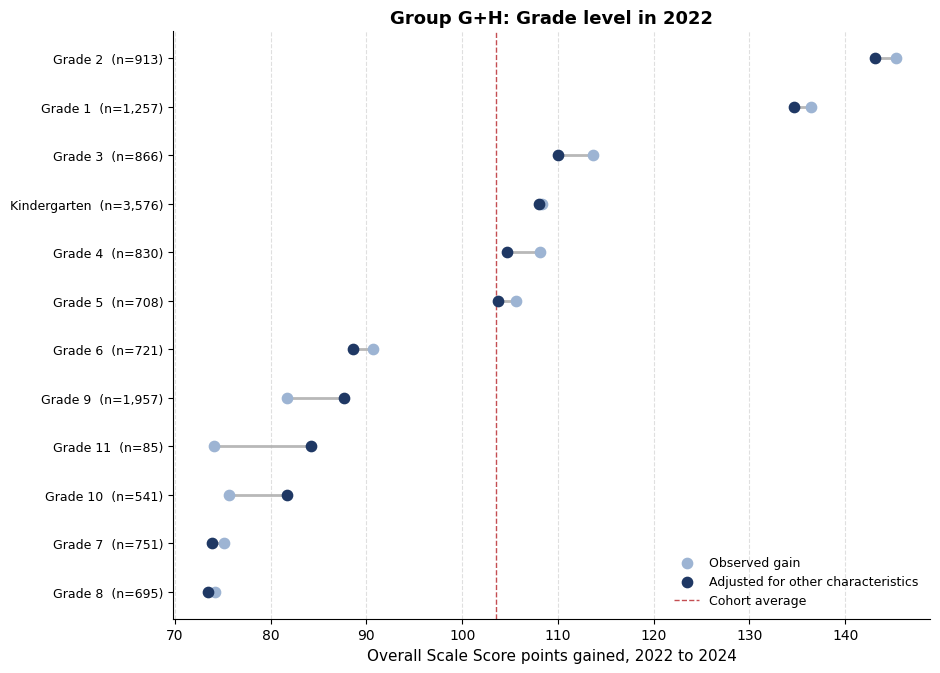

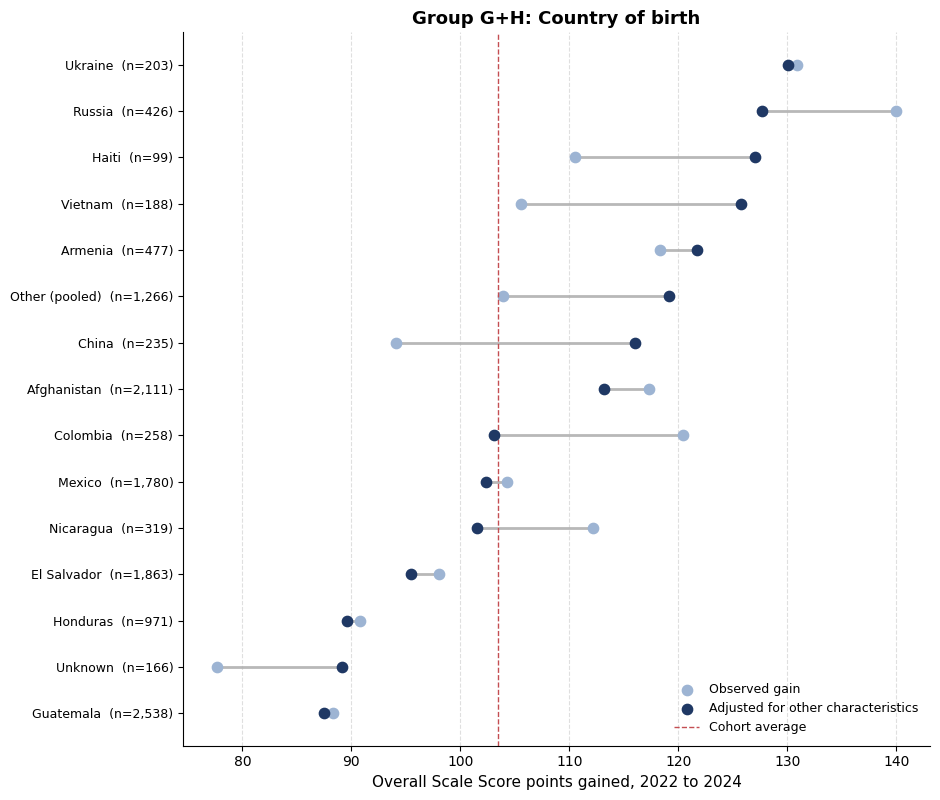

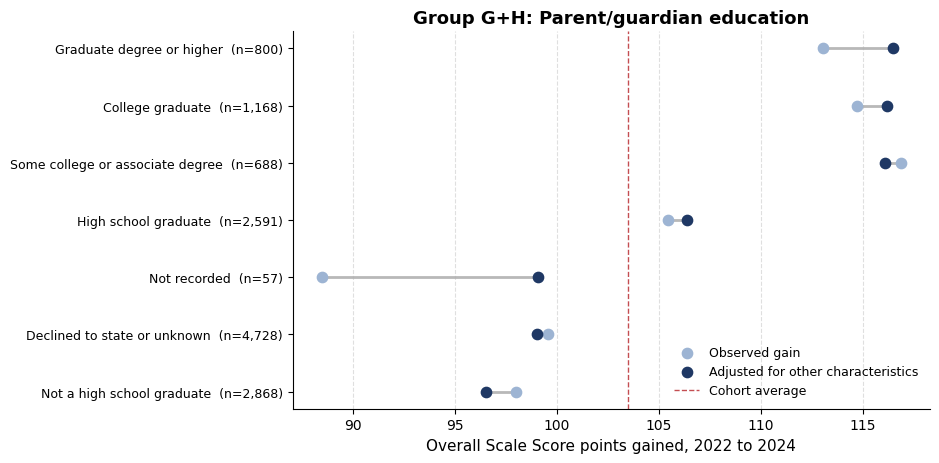

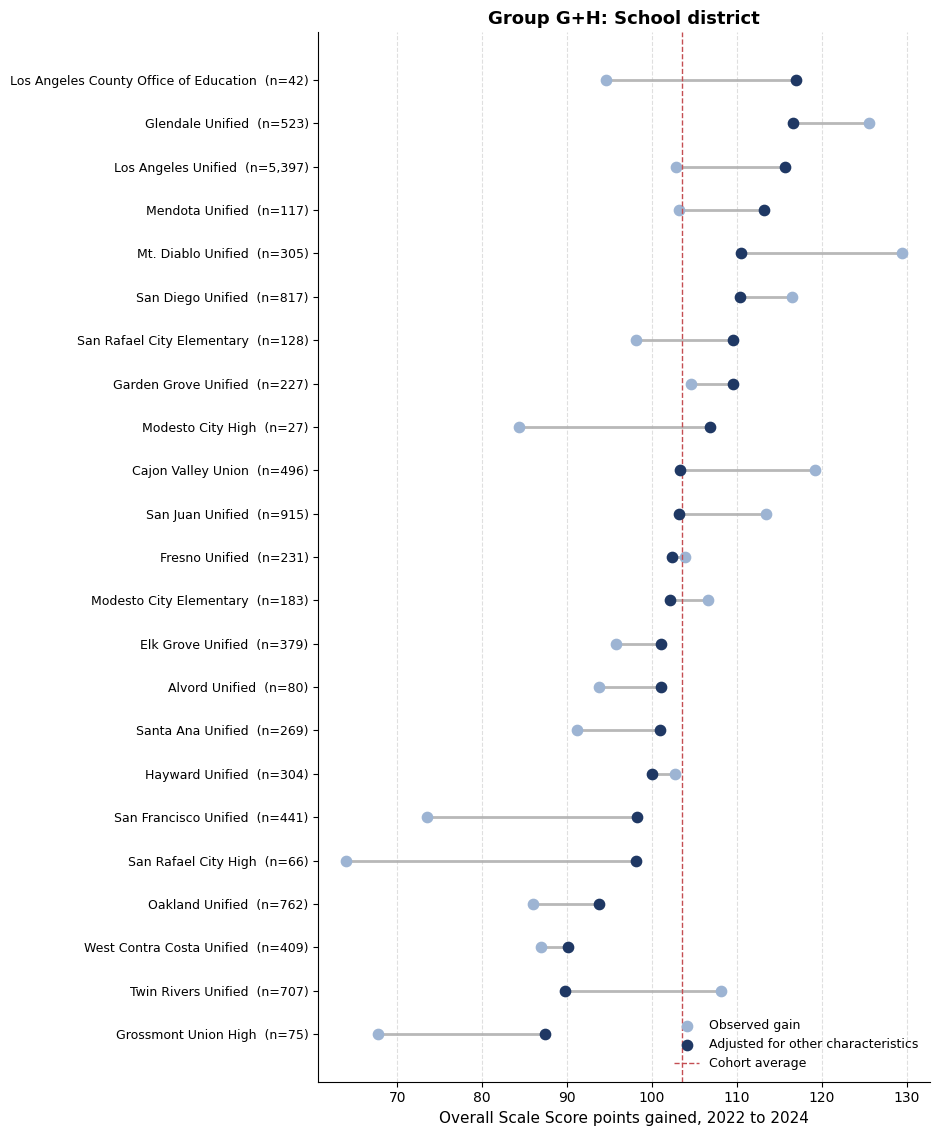

In [23]:
# %% [Cell C] One figure per characteristic: observed and adjusted on the same axis
import matplotlib.pyplot as plt

def dumbbell(t, title, fname):
    t = t.sort_values("Adjusted").reset_index(drop=True)
    y = np.arange(len(t))
    fig, ax = plt.subplots(figsize=(9.5, 0.42 * len(t) + 1.8))
    ax.hlines(y, t["Observed"], t["Adjusted"], color="#B8B8B8", lw=2, zorder=1)
    ax.scatter(t["Observed"], y, s=55, color="#9DB4D3", label="Observed gain", zorder=2)
    ax.scatter(t["Adjusted"], y, s=55, color="#1F3864",
               label="Adjusted for other characteristics", zorder=3)
    ax.axvline(model_df[OUTCOME].mean(), color="#C44E52", ls="--", lw=1, label="Cohort average")
    ax.set_yticks(y)
    ax.set_yticklabels([f"{l}  (n={n:,})" for l, n in zip(t["Label"], t["Students"])], fontsize=9)
    ax.set_xlabel("Overall Scale Score points gained, 2022 to 2024", fontsize=11)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.grid(axis="x", ls="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=9, loc="lower right", frameon=False)
    plt.tight_layout()
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()

TITLES = {"Grade": "Grade level in 2022", "BirthCountry": "Country of birth",
          "ParentEd": "Parent/guardian education", "Race": "Race and ethnicity",
          "Language": "Primary language", "Gender": "Gender",
          "SED": "Socioeconomically disadvantaged", "Migrant": "Migrant status",
          "Homeless": "Homeless program"}

for var in ["Grade", "BirthCountry", "ParentEd"]:
    dumbbell(oa[var], f"{group_label}: {TITLES[var]}", f"plots/{group_short}_obs_adj_{var}.png")
dumbbell(dist, f"{group_label}: School district", f"plots/{group_short}_obs_adj_District.png")



In [24]:
# %% [Cell D] Robustness: which rankings hold in grade-standardized SD units too?
# Fits the SD-unit version alongside, so the appendix can state plainly which
# findings do not depend on the choice of metric.

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sd_model = smf.mixedlm(build_formula("ZGain_fixed", "Z1_fixed", model_cats),
                           data=model_df, groups="District").fit(reml=True, method="lbfgs", maxiter=2000)

rows = []
for var in model_cats:
    a = observed_vs_adjusted(full_model, model_df, var, OUTCOME).set_index(var)["Adjusted"]
    b = observed_vs_adjusted(sd_model, model_df, var, "ZGain_fixed").set_index(var)["Adjusted"].reindex(a.index)
    ra, rb = a.rank(ascending=False, method="min"), b.rank(ascending=False, method="min")
    movers = [f"{pretty(var, l)} ({int(ra[l])} to {int(rb[l])})" for l in a.index if abs(ra[l] - rb[l]) >= 3]
    rows.append({"Characteristic": var, "Levels": len(a),
                 "Rank agreement, points vs SD (rho)": round(a.corr(b, method="spearman"), 2) if len(a) > 2 else None,
                 "Levels moving 3+ places": "; ".join(movers) or "none"})

sd_re = {d: float(np.asarray(v).ravel()[0]) for d, v in sd_model.random_effects.items()}
d_rho = dist.set_index("District")["District_effect"].corr(pd.Series(sd_re), method="spearman")
rows.append({"Characteristic": "District", "Levels": len(dist),
             "Rank agreement, points vs SD (rho)": round(d_rho, 2), "Levels moving 3+ places": "(see Cell B)"})

robust = pd.DataFrame(rows)
print(robust.to_string(index=False))
robust.to_csv(f"robustness_points_vs_sd_{group_short}.csv", index=False)

Characteristic  Levels  Rank agreement, points vs SD (rho)                                                                                                             Levels moving 3+ places
         Grade      12                                0.31 Grade 2 (1 to 6); Grade 1 (2 to 8); Kindergarten (4 to 10); Grade 4 (5 to 1); Grade 5 (6 to 3); Grade 9 (8 to 2); Grade 11 (9 to 4)
      ParentEd       7                                0.82                                                                                                                                none
          Race       8                                0.98                                                                                                                                none
  BirthCountry      15                                1.00                                                                                                                                none
      Language       3                       